# GDP per Capita and Internet Usage Rate Effects on AI Threat Perception among Developers

By Team B04: Steven Nguyen, Ilya Barymov, YC Hsu, Muhammad Rafi

## 1. Introduction and Motivation



**The goal of the project is to answer the questions below:**

**Stakeholders:**

*   Government policymakers: those that shaping AI, labor and education policy
*   Global employers: leaders with devloper teams.

**Decision:** Track how developers feel about AI overtime, how much they use it, and pair AI adoption with upskilling so that employees not only deliver value but feel valued.

**Questions:**
1. Is a country's GDP per capita linked to how much its developers trust AI and feel threatened by it?
2. Is a country's internet usage rate linked to the same perceptions?

**Data source:**

1. Stack Overflow Developer Survey (https://github.com/StackExchange/Survey/tree/main/packages/archive) - (The Github includes Stack Overflow data from 2011-2025, however as of now the team is choosing to only use 2025 survey data.): Open Database License
2. GDP Per Capita (https://data.worldbank.org/indicator/NY.GDP.PCAP.CD), downloaded as XLS/CSV from the link.
3. Internet Usage Rate (https://data.worldbank.org/indicator/IT.NET.USER.ZS), downloaded as XLS/CSV from the link.
4. All files are stored in our Google Cloud Storage bucket ba780-ai-trust-data/Datasets/. The professor and TA have been given access so the notebook can run with "Restart & Run All".

With this project, the team hopes to understand how developers perceive AI as a threat and what national factors shape that perception. We hope our findings contribute meaningful insights to the ongoing conversation around AI's perceived risk to the workforce.

## Executive Summary

AI tools are reshaping work the world around us everyday, which makes it more important than ever to separate what is actually happening from fear and perception. Employers, educators, and government policymakers especially need to take the extra step and understand how their developers, students, and citizens truly feel. Today, we are focused primarily on developers. To answer our hypothesis about whether a country's wealth and internet connectivity are linked to how its developers perceive AI, we combined the Stack Overflow Developer Survey from 2025 with 2 separate World Bank datasets: GDP per capita and internet usage data, which covers 22,753 professional developers in 65 countries after data cleaning.

We quantified qualitative survey data and used country level data to measure Pearson correlations against GDP per capita and internet usage, compared countries across GDP groups, internet usage groups, and World Bank regions, and used trend lines to flag countries that are outliers. We found that developers in poorer (low GDP countries) and less connected countries (less internet users) are more likely to see AI as a threat to their job (17.8% in the poorest of countries vs. 10.8% in the richest). In addition, these same developers also use AI tools more often (73.4% use AI daily in the poorest countries vs. 47.0% in the richest) and trust them more (77.2% vs. 33.7%), so developers who rely on AI the most are also the ones most worried about it. This means that in lower income countries the worry is not about AI adoption  but helping them feel secure and valued alongside AI growth.

We recommend that policymakers and companies track how developers feel about AI, how much they use it, and pair AI adoption with upskilling so that employees not only deliver value but feel valued. Our country and regional results show who is most at risk of feeling AI as a threat to their job security: lower income countries and regions like South Asia, where developers feel the highest threatened levels.

## 2. Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import auth

## 3. Loading Data

In [ ]:
auth.authenticate_user()

!gcloud config set project ba780-ai-trust

BUCKET = "ba780-ai-trust-data"
PATH = f"gs://{BUCKET}/Datasets/"

STACK_OVERFLOW_FILE  = PATH + "Stack Overflow/results.txt"
GDP_FILE             = PATH + "GDP/GDP Per Capita.xls"
INTERNET_USAGE_FILE  = PATH + "Internet Usage/Internet Usage.csv"
COUNTRY_MAPPING_FILE = PATH + "Country_Mapping.xlsx"

# Stack Overflow Developer Survey 2025
stack_overflow_raw_data = pd.read_csv(STACK_OVERFLOW_FILE, low_memory=False)

# GDP per capita, World Bank
gdp_raw_data  = pd.read_excel(GDP_FILE, sheet_name="Data", skiprows=3)
gdp_meta_data = pd.read_excel(GDP_FILE, sheet_name="Metadata - Countries")

# Internet usage rate
internet_usage_raw_data = pd.read_csv(INTERNET_USAGE_FILE, skiprows=4)

# Mapping for future merging
country_mapping_raw_data = pd.read_excel(COUNTRY_MAPPING_FILE)

print(f"Stack Overflow: {stack_overflow_raw_data.shape}")
print(f"GDP:            {gdp_raw_data.shape}")
print(f"GDP metadata:   {gdp_meta_data.shape}")
print(f"Internet usage: {internet_usage_raw_data.shape}")

[environment: untagged] Read more to tag: g.co/cloud/project-env-tag.
Updated property [core/project].
Stack Overflow: (49191, 172)
GDP:            (265, 70)
GDP metadata:   (264, 5)
Internet usage: (265, 71)


## 4. Data Cleaning

### 4.1 Stack Overflow

In [ ]:
stack_overflow_raw_data.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


We have 49191 rows and 172 columns of data. Let's take a look at the columns and leave only those columns that we need for our research.

In [ ]:
key_columns = [
    "ResponseId",           # unique respondent ID
    "MainBranch",           # developer status
    "Country",              # country of residence
    "AISelect",             # uses AI tools? how often (daily / weekly / monthly / no)
    "AISent",               # general attitude to AI tools (favorable ... unfavorable)
    "AIThreat",             # is AI a threat to your job?
    "AIAcc",                # trust in AI accuracy
    "AIComplex",            # how well AI handles complex tasks?
    "YearsCode",            # total years of coding, incl. education
    "DevType",              # job role
    "AIAgents",             # uses AI agents?
    "AIAgentChange",        # did AI/agents change how they work?
    "LearnCodeAI",          # learned AI tools in the past year?
    "AIFrustration"         # problems with AI
]

In [ ]:
stack_overflow_data = stack_overflow_raw_data[key_columns].copy()
stack_overflow_data.head()

,ResponseId,MainBranch,Country,AISelect,AISent,AIThreat,AIAcc,AIComplex,YearsCode,DevType,AIAgents,AIAgentChange,LearnCodeAI,AIFrustration
0,1,I am a developer by profession,Ukraine,"Yes, I use AI tools monthly or infrequently",Indifferent,I'm not sure,Neither trust nor distrust,Bad at handling complex tasks,14.0,"Developer, mobile","Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not quite"
1,2,I am a developer by profession,Netherlands,"Yes, I use AI tools weekly",Indifferent,I'm not sure,Neither trust nor distrust,Bad at handling complex tasks,10.0,"Developer, back-end","No, and I don't plan to",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu..."
2,3,I am a developer by profession,Ukraine,"Yes, I use AI tools daily",Favorable,No,Somewhat trust,Neither good or bad at handling complex tasks,12.0,"Developer, front-end","Yes, I use AI agents at work weekly","Yes, somewhat","Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu..."
3,4,I am a developer by profession,Ukraine,"Yes, I use AI tools weekly",Favorable,No,Somewhat trust,Bad at handling complex tasks,5.0,"Developer, back-end","Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu..."
4,5,I am a developer by profession,Ukraine,"Yes, I use AI tools weekly",Favorable,No,Neither trust nor distrust,"Good, but not great at handling complex tasks",22.0,Engineering manager,"No, and I don't plan to","Yes, to a great extent","Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not quite"


Now let's check our data for missing values.

In [ ]:
stack_overflow_data.notna().sum()

,0
ResponseId,49191
MainBranch,49191
Country,35437
AISelect,33720
AISent,33467
AIThreat,36078
AIAcc,33297
AIComplex,33283
YearsCode,43042
DevType,43680


Country and AIAcc are the most important features for our research should we should definetly drop all the rows that have missing values there. All of the other features are fullflled at least for 30000 rows each, so we can just try dropping all the rows that have at least one missing value and see how many rows are left.

In [ ]:
rows_before = len(stack_overflow_data)
rows_after = len(stack_overflow_data.dropna())
print(f"Rows before dropping missing values: {rows_before}.")
print(f"Rows after dropping missing values: {rows_after}.")

print(f"It is {round(((rows_before - rows_after) / rows_before * 100), 2)}% rows that have missing values. Cleaned dataset has {rows_after} rows.")

stack_overflow_data = stack_overflow_data.dropna()

Rows before dropping missing values: 49191.
Rows after dropping missing values: 29893.
It is 39.23% rows that have missing values. Cleaned dataset has 29893 rows.


In [ ]:
columns_to_check = ["MainBranch",
                    "AISelect",
                    "AISent",
                    "AIThreat",
                    "AIAcc",
                    "AIComplex",
                    "AIAgents",
                    "AIAgentChange",
                    "LearnCodeAI",
                    "AIFrustration"]
for col in columns_to_check:
  if col == 'AIFrustration':
    values = stack_overflow_data[col].str.split(";").explode()
  else:
    values = stack_overflow_data[col]

  print(f"===== {col} | {values.unique()} =====")
  print()

===== MainBranch | ['I am a developer by profession'
 'I am not primarily a developer, but I write code sometimes as part of my work/studies'
 'I used to be a developer by profession, but no longer am'
 'I work with developers or my work supports developers but am not a developer by profession'
 'I am learning to code' 'I code primarily as a hobby'] =====

===== AISelect | ['Yes, I use AI tools monthly or infrequently'
 'Yes, I use AI tools weekly' 'Yes, I use AI tools daily'
 "No, and I don't plan to" 'No, but I plan to soon'] =====

===== AISent | ['Indifferent' 'Favorable' 'Very favorable' 'Unfavorable'
 'Very unfavorable' 'Unsure'] =====

===== AIThreat | ["I'm not sure" 'No' 'Yes'] =====

===== AIAcc | ['Neither trust nor distrust' 'Somewhat trust' 'Somewhat distrust'
 'Highly distrust' 'Highly trust'] =====

===== AIComplex | ['Bad at handling complex tasks'
 'Neither good or bad at handling complex tasks'
 'Good, but not great at handling complex tasks'
 'Very poor at handling c

Let's remove all the values that are useless for our research.

In [ ]:
def remove_rows(data, mask):
  return data[~mask]

stack_overflow_clean = stack_overflow_data.copy()

# Keep only professional developers
stack_overflow_clean = remove_rows(
    stack_overflow_clean,
    stack_overflow_clean["MainBranch"] != "I am a developer by profession")

stack_overflow_clean.shape

(23624, 14)

Let's check distribution of YearsCode value and remove obvious outliers. For instance, 99 year of coding experience is impossible.

In [ ]:
stack_overflow_clean["YearsCode"].describe()

,YearsCode
count,23624.000000
mean,17.976168
std,10.943969
min,1.000000
25%,10.000000
50%,15.000000
75%,25.000000
max,100.000000


In [ ]:
years_groups = pd.cut(
    stack_overflow_clean["YearsCode"],
    bins=[0, 10, 20, 30, 40, 50, 65, 100],
    labels=["1-10", "11-20", "21-30", "31-40", "41-50", "51-65", "66-100"]
)

years_groups.value_counts().sort_index().rename_axis("Years of coding").to_frame("Developers")

,Developers
Years of coding,
1-10,7458
11-20,8465
21-30,4631
31-40,2162
41-50,843
51-65,58
66-100,7


There are some obvious outliers. We cannot rely on those responses, so it better to drop them as well.

In [ ]:
stack_overflow_clean = remove_rows(stack_overflow_clean, stack_overflow_clean["YearsCode"] > 65)
stack_overflow_clean.shape

(23617, 14)

**4.1.1 Stack Overflow Data Summary & Keytakeaway:**
The raw survey has 49,191 responses and 172 columns. We kept 14 columns related to the respondent, their country, and their views on AI. Dropping rows with any missing value removed 39% of responses. We then kept only professional developers, because the AI threat question asks about the respondent's current job. Finally, we removed 7 responses with more than 65 years of coding experience, which is not realistic. The cleaned Stack Overflow table has 23,617 professional developers with complete answers.

### 4.2 GDP Per Capita

In [ ]:
gdp_raw_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,27441.550214,28440.041688,30082.158423,30654.485124,22664.370995,26827.344787,31000.571380,34897.618393,38590.565029,NaN
1,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,186.089515,186.909365,197.367876,225.400456,208.963066,226.836513,...,1335.743165,1529.923080,1553.617944,1508.031525,1351.503167,1560.894626,1675.902524,1571.132704,1628.227289,1722.385620
2,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,522.082216,525.469771,491.337221,496.602504,510.787063,356.496214,357.261153,413.757895,416.871146,NaN
3,Africa Western and Central,AFW,GDP per capita (current US$),NY.GDP.PCAP.CD,121.936832,127.451040,133.823783,139.004980,148.551510,155.587905,...,1632.424978,1577.203497,1723.114463,2219.412555,2034.437940,2116.938294,2143.072094,1846.246811,1416.228412,1600.058374
4,Angola,AGO,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2082.373436,2832.149980,2891.830324,2507.868072,1749.179484,2266.968349,3598.536691,2885.513491,2720.819007,3129.476623


In [ ]:
gdp_meta_data.head()

,Country Code,Region,IncomeGroup,SpecialNotes,TableName
0,ABW,Latin America & Caribbean,High income,NaN,Aruba
1,AFE,NaN,NaN,"26 countries, stretching from the Red Sea in t...",Africa Eastern and Southern
2,AFG,Middle East & North Africa,Low income,The reporting period for national accounts dat...,Afghanistan
3,AFW,NaN,NaN,"22 countries, stretching from the westernmost ...",Africa Western and Central
4,AGO,Sub-Saharan Africa,Lower middle income,The World Bank systematically assesses the app...,Angola


We keep only 2025 GDP per capita because the survey was conducted in 2025.

In [ ]:
gdp_raw_data_2025 = gdp_raw_data[['Country Name', 'Country Code', '2025']].copy()

gdp_raw_data_2025.info()
gdp_raw_data_2025.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  265 non-null    object 
 1   Country Code  265 non-null    object 
 2   2025          233 non-null    float64
dtypes: float64(1), object(2)
memory usage: 6.3+ KB


,Country Name,Country Code,2025
0,Aruba,ABW,NaN
1,Africa Eastern and Southern,AFE,1722.385620
2,Afghanistan,AFG,NaN
3,Africa Western and Central,AFW,1600.058374
4,Angola,AGO,3129.476623


Merging the table with an existing tab labeled "region" using the "country code" coloumn. The reason for the merge is that we need to create a cleaned table with only countries. Right now the table has both countries and regions.

In [ ]:
gdp_raw_data_2025 = gdp_raw_data_2025.merge(gdp_meta_data[['Country Code', 'Region']], on='Country Code', how='left')
gdp_raw_data_2025 = gdp_raw_data_2025.dropna(subset=['Region'])

gdp_raw_data_2025.info()
gdp_raw_data_2025.head()

<class 'pandas.core.frame.DataFrame'>
Index: 217 entries, 0 to 264
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  217 non-null    object 
 1   Country Code  217 non-null    object 
 2   2025          186 non-null    float64
 3   Region        217 non-null    object 
dtypes: float64(1), object(3)
memory usage: 8.5+ KB


,Country Name,Country Code,2025,Region
0,Aruba,ABW,NaN,Latin America & Caribbean
2,Afghanistan,AFG,NaN,Middle East & North Africa
4,Angola,AGO,3129.476623,Sub-Saharan Africa
5,Albania,ALB,12998.147870,Europe & Central Asia
6,Andorra,AND,54291.502603,Europe & Central Asia


The table has both regions and countries together. The regions need to be removed. Rows with no Region are regional and income group aggregates (for example: World Euro area, High Income, etc).

In [ ]:
has_data_mask = gdp_raw_data_2025['2025'].notna()

gdp_raw_with_data = gdp_raw_data_2025[has_data_mask].copy()
gdp_raw_no_data = gdp_raw_data_2025[~has_data_mask].copy()

print(gdp_raw_with_data.shape)
print(gdp_raw_no_data.shape)
gdp_raw_no_data

(186, 4)
(31, 4)


,Country Name,Country Code,2025,Region
0,Aruba,ABW,NaN,Latin America & Caribbean
2,Afghanistan,AFG,NaN,Middle East & North Africa
8,United Arab Emirates,ARE,NaN,Middle East & North Africa
11,American Samoa,ASM,NaN,East Asia & Pacific
23,"Bahamas, The",BHS,NaN,Latin America & Caribbean
27,Bermuda,BMU,NaN,North America
38,Channel Islands,CHI,NaN,Europe & Central Asia
50,Cuba,CUB,NaN,Latin America & Caribbean
51,Curacao,CUW,NaN,Latin America & Caribbean
52,Cayman Islands,CYM,NaN,Latin America & Caribbean


In [ ]:
gdp_raw_with_data['Country Code'].duplicated().sum()

np.int64(0)

In [ ]:
gdp_clean = gdp_raw_with_data.rename(columns={"2025": "GDP_Per_Capita"})
gdp_clean.head()

,Country Name,Country Code,GDP_Per_Capita,Region
4,Angola,AGO,3129.476623,Sub-Saharan Africa
5,Albania,ALB,12998.147870,Europe & Central Asia
6,Andorra,AND,54291.502603,Europe & Central Asia
9,Argentina,ARG,14898.088594,Latin America & Caribbean
10,Armenia,ARM,9474.018493,Europe & Central Asia


Now, this line of code checks for duplates in Country Name.

In [ ]:
gdp_clean.info()
gdp_clean.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 186 entries, 4 to 264
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    186 non-null    object 
 1   Country Code    186 non-null    object 
 2   GDP_Per_Capita  186 non-null    float64
 3   Region          186 non-null    object 
dtypes: float64(1), object(3)
memory usage: 7.3+ KB


,GDP_Per_Capita
count,186.000000
mean,19522.795582
std,26068.774191
min,233.823013
25%,3057.818751
50%,7882.448894
75%,26788.998550
max,147252.179122


The last step here gives us a close up on the data and verifies the data is cleaned.

**4.2.1 GDP Per Capita Data Cleaning Summary and Keytakeaway:** To clean the GDP Bank Data, we kept only the 2025 column to match the StackOverflow survey year, removed 48 regions as we only wanted the countries, and dropped the 31 countries with no value, which leaves 186 countries with no duplicate country codes. This matters because every GDP comparison in Section 6 depends on each developer's country matching exactly one GDP figurs. From initial EDA we can see that the values are heavily right skewed.

### 4.3 Internet Usage

In [ ]:
internet_usage_raw_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,97.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,17.30,19.600000,21.600000,23.5000,25.000000,26.800000,27.800000,28.800000,30.4,NaN
2,Afghanistan,AFG,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,13.50,16.799999,17.600000,17.0485,16.514299,15.866300,15.928400,16.094999,NaN,NaN
3,Africa Western and Central,AFW,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,23.80,25.700000,28.500000,31.5000,34.700000,37.500000,38.500000,40.000000,42.4,NaN
4,Angola,AGO,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,26.00,29.000000,32.129398,33.3209,34.556499,35.838001,37.885899,40.704800,NaN,NaN


In [ ]:
internet_usage_raw_data[["2022", "2023", "2024", "2025"]].isna().sum()

,0
2022,51
2023,52
2024,51
2025,223


2025 is missing for 223 of 265 rows, so we use 2024, the latest year with good coverage.

We keep only 2024, drop countries without a value, and remove regional aggregates.

In [ ]:
internet_usage_2024 = (
    internet_usage_raw_data[["Country Name", "Country Code", "2024"]]
    .rename(columns={"2024": "Internet_Usage_Pct"})
    .dropna(subset=["Internet_Usage_Pct"])
)

real_countries = gdp_meta_data.loc[gdp_meta_data["Region"].notna(), "Country Code"]
internet_usage_2024 = internet_usage_2024[internet_usage_2024["Country Code"].isin(real_countries)]

print(internet_usage_2024.shape)
internet_usage_2024.describe()

(182, 3)


,Internet_Usage_Pct
count,182.000000
mean,72.541809
std,25.028044
min,8.596000
25%,59.367650
50%,82.103397
75%,91.997773
max,100.000000


This step displays the first 5 rows for inspection

In [ ]:
internet_usage_2024.head()

,Country Name,Country Code,Internet_Usage_Pct
2,Afghanistan,AFG,16.094999
4,Angola,AGO,40.704800
5,Albania,ALB,85.863899
6,Andorra,AND,94.397598
8,United Arab Emirates,ARE,100.000000


**4.3.1 Internet Usage Data Cleaning Summary and Keytakeaway:** To address missingness in 2025 data (absent in 223 of 265 rows), we restricted the dataset to 2024, the most recent year with complete coverage. We cleaned the dataset by dropping countries with missing values and filtered out regional totals so we only keep actual countries. Finally, we inspected the first 5 rows to confirm correct data formatting and alignment prior to quantile grouping.

### 4.4 Country Name Matching

The Stack Overflow country names are different from the World Bank names. We use our country mapping table based on World Bank to add two new columns: Country_Code (for merging) and Country_WB (for chart labels). We keep the original Country column as before/after evidence.

In [ ]:
print(f"Country mapping: {country_mapping_raw_data.shape}")

Country mapping: (217, 5)


In [ ]:
mapping = country_mapping_raw_data.copy()
print(mapping.shape)
mapping.head()

(217, 5)


,World Bank Country Code,World Bank Country Name,GDP Country Name,Internet Usage Country Name,2025 Stack Overflow Country Label(s)
0,ABW,Aruba,Aruba,Aruba,NaN
1,AFG,Afghanistan,Afghanistan,Afghanistan,Afghanistan
2,AGO,Angola,Angola,Angola,Angola
3,ALB,Albania,Albania,Albania,Albania
4,AND,Andorra,Andorra,Andorra,Andorra


In [ ]:
mapping = mapping.dropna(subset=["2025 Stack Overflow Country Label(s)"])

to_code = {}
to_name = {}
for i, row in mapping.iterrows():
    # some countries have several Stack Overflow names separated by ";"
    for name in row["2025 Stack Overflow Country Label(s)"].split(";"):
        to_code[name.strip()] = row["World Bank Country Code"]
        to_name[name.strip()] = row["World Bank Country Name"]

print("Stack Overflow names in the mapping:", len(to_code))

Stack Overflow names in the mapping: 185


In [ ]:
stack_overflow_clean = stack_overflow_clean.copy()
stack_overflow_clean["Country_Code"] = stack_overflow_clean["Country"].map(to_code)
stack_overflow_clean["Country_WB"] = stack_overflow_clean["Country"].map(to_name)

print("Countries without a World Bank code:")
print(stack_overflow_clean.loc[stack_overflow_clean["Country_Code"].isna(), "Country"].value_counts())

Countries without a World Bank code:
Country
Taiwan     80
Nomadic    12
Name: count, dtype: int64


"Nomadic" is not a country, so we remove it here.

In [ ]:
before = len(stack_overflow_clean)
stack_overflow_clean = stack_overflow_clean[stack_overflow_clean["Country"] != "Nomadic"]
print(f"Removed 'Nomadic': {before - len(stack_overflow_clean)} rows | rows left: {len(stack_overflow_clean)}")

Removed 'Nomadic': 12 rows | rows left: 23605


In [ ]:
changed = (stack_overflow_clean[["Country", "Country_WB", "Country_Code"]]
           .drop_duplicates()
           .query("Country != Country_WB")
           .sort_values("Country"))
print(f"{len(changed)} country names changed:")
print(changed.to_string(index=False))

28 country names changed:
                                             Country                Country_WB Country_Code
                           Congo, Republic of the...               Congo, Rep.          COG
                                      Czech Republic                   Czechia          CZE
                                       Côte d'Ivoire             Cote d'Ivoire          CIV
               Democratic People's Republic of Korea Korea, Dem. People's Rep.          PRK
                    Democratic Republic of the Congo          Congo, Dem. Rep.          COD
                                               Egypt          Egypt, Arab Rep.          EGY
                                  Hong Kong (S.A.R.)      Hong Kong SAR, China          HKG
                        Iran, Islamic Republic of...        Iran, Islamic Rep.          IRN
                                          Kyrgyzstan           Kyrgyz Republic          KGZ
                    Lao People's Democratic Republic  

In [ ]:
n = stack_overflow_clean["Country_Code"].value_counts()
print(f"{len(n)} countries with a code, {(n >= 30).sum()} of them have at least 30 answers")

161 countries with a code, 66 of them have at least 30 answers


**4.4.1 Country Name Mapping Summary and Keytakeaway:**

On comparison of the country names with the World Bank data it was found that 28 of the names had to be changed; 12 of the entries marked 'Nomadic' were deleted since 'Nomadic' is not the name of a country, leaving 23,605 developers. There were also 80 developers from Taiwan who could not be matched with the World Bank data.

### 4.5 Data Cleaning Summary

We split the cleaning by datasets: 2 students did the Stack Overflow dataset, 1 student did the GDP dataset, 1 student did the Internet Usage dataset.

- **Stack Overflow (4.1):** We kept 14 of 172 columns because we find them useful for our research, dropped rows with missing values (39%), and kept only professional developers. We also removed outliers with more than 65 years of coding, which is obviously not real.
- **GDP per capita (4.2):** We kept only 2025 because the survey was done in 2025. We removed region and income group rows, and 31 countries with no 2025 value, which left 186 countries.
- **Internet usage (4.3):** We used 2024 because 2025 is missing for 223 of 265 rows. After removing region rows and missing values, 182 countries were left.
- **Country names (4.4):** The mapping table was applied in order to match the country names from Stack Overflow with those from the World Bank together with their codes. It is important to carry out this step when combining the two datasets since certain countries have different names in the two sources. A total of 28 name changes were carried out. Twelve of the entries classified as 'Nomadic' were deleted, thereby leaving 23,605 developers. Taiwan still had 80 responses with no matching World Bank code.

| Dataset | Before | After | What we did |
|---|---|---|---|
| Stack Overflow 2025 | 49,191 rows, 172 columns | 23,605 rows, 14 columns (+2 new) | Kept 14 columns, dropped rows with missing values (39%), kept professional developers only, removed YearsCode above 65, removed "Nomadic" |
| GDP per capita | 265 rows | 186 countries | Kept 2025 only, removed region and income group rows, removed countries with no 2025 value |
| Internet usage | 265 rows | 182 countries | Used 2024 because 2025 is missing for 223 rows, removed region rows and missing values |
| Country mapping | 217 countries | 185 Stack Overflow labels | Matched Stack Overflow names to World Bank codes, fixed some spelling and encoding issues |

**4.5.1 Key Takeaway:** After cleaning, all three datasets use the same World Bank country codes, so we can merge them on one column.

## 5. Merging and Enriching

### 5.1 Merging

First, let's rename some columns for merging.

In [ ]:
gdp_for_merge = gdp_clean[["Country Code", "GDP_Per_Capita", "Region"]].rename(columns={"Country Code": "Country_Code"})
internet_for_merge = internet_usage_2024[["Country Code", "Internet_Usage_Pct"]].rename(columns={"Country Code": "Country_Code"})

We use inner joins on Country_Code, so only countries present in all three datasets remain.

In [ ]:
merged_data = (
    stack_overflow_clean
    .merge(gdp_for_merge,      on="Country_Code", how="inner")
    .merge(internet_for_merge, on="Country_Code", how="inner")
)

print(f"Rows before merge: {len(stack_overflow_clean)}")
print(f"Rows after merge:  {len(merged_data)}")
print(f"Countries:         {merged_data['Country_Code'].nunique()}")

Rows before merge: 23605
Rows after merge:  23406
Countries:         145


In [ ]:
lost = stack_overflow_clean[~stack_overflow_clean["Country_Code"].isin(merged_data["Country_Code"])]
print(f"Rows lost in merge: {len(lost)}")
lost["Country"].value_counts().head(10)

Rows lost in merge: 199


,count
Country,
Taiwan,80
United Arab Emirates,46
Lebanon,16
Isle of Man,10
Syrian Arab Republic,9
Yemen,8
Cuba,6
Afghanistan,5
Myanmar,5


We keep only countries with at least 30 respondents. It will make our research stronger.

In [ ]:
merged_data["Country_Respondents"] = merged_data.groupby("Country_Code")["ResponseId"].transform("count")
merged_data = merged_data[merged_data["Country_Respondents"] >= 30]

print(f"Rows:      {len(merged_data)}")
print(f"Countries: {merged_data['Country_Code'].nunique()}")

Rows:      22753
Countries: 65


In [ ]:
merged_data.head()

,ResponseId,MainBranch,Country,AISelect,AISent,AIThreat,AIAcc,AIComplex,YearsCode,DevType,AIAgents,AIAgentChange,LearnCodeAI,AIFrustration,Country_Code,Country_WB,GDP_Per_Capita,Region,Internet_Usage_Pct,Country_Respondents
0,1,I am a developer by profession,Ukraine,"Yes, I use AI tools monthly or infrequently",Indifferent,I'm not sure,Neither trust nor distrust,Bad at handling complex tasks,14.0,"Developer, mobile","Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not quite",UKR,Ukraine,5865.884766,Europe & Central Asia,82.474899,683
1,2,I am a developer by profession,Netherlands,"Yes, I use AI tools weekly",Indifferent,I'm not sure,Neither trust nor distrust,Bad at handling complex tasks,10.0,"Developer, back-end","No, and I don't plan to",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu...",NLD,Netherlands,73683.917133,Europe & Central Asia,97.006798,629
2,3,I am a developer by profession,Ukraine,"Yes, I use AI tools daily",Favorable,No,Somewhat trust,Neither good or bad at handling complex tasks,12.0,"Developer, front-end","Yes, I use AI agents at work weekly","Yes, somewhat","Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu...",UKR,Ukraine,5865.884766,Europe & Central Asia,82.474899,683
3,4,I am a developer by profession,Ukraine,"Yes, I use AI tools weekly",Favorable,No,Somewhat trust,Bad at handling complex tasks,5.0,"Developer, back-end","Yes, I use AI agents at work monthly or infreq...",Not at all or minimally,"Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not qu...",UKR,Ukraine,5865.884766,Europe & Central Asia,82.474899,683
4,5,I am a developer by profession,Ukraine,"Yes, I use AI tools weekly",Favorable,No,Neither trust nor distrust,"Good, but not great at handling complex tasks",22.0,Engineering manager,"No, and I don't plan to","Yes, to a great extent","Yes, I learned how to use AI-enabled tools for...","AI solutions that are almost right, but not quite",UKR,Ukraine,5865.884766,Europe & Central Asia,82.474899,683


**5.1 Merging Data Summary:** We joined the cleaned Stack Overflow table with the GDP and internet usage tables on the World Bank country code, using inner joins so that every developer has both country values. The merge kept 23,406 of 23,605 developers from 145 countries. The 199 lost respondents come from Taiwan, which has no World Bank data, and from countries with no 2025 GDP value, such as the United Arab Emirates, Lebanon and Cuba. We then removed countries with fewer than 30 respondents, because percentages based on very few answers are unreliable. This dropped 80 small countries and 653 developers. The final table has 22,753 professional developers from 65 countries, and each row includes the developer's survey answers, GDP per capita and internet usage.

### 5.2 Enriching: LLM Scores for AI Trust and AI Job Concern

Almost all AI questions in the survey are multiple choice. We decided to use AI to score each response. We will use OpenAI API for creating two columns:

- **LLM_Trust**: how much the developer trusts AI tools (1 = no trust, 10 = maximum trust)
- **LLM_Concern**: how worried the developer is that AI threatens their job or career (1 = not worried, 10 = maximum worry)

With the help of Claude we created instructions for the LLM to use. These instructions were validated by the team.

To avoid wasting money we decided to develop a system which allows us to control calling API. If we do not need to do that but still want to run the notebook, it will just load the saved scores from Google Cloud.
- RUN_LLM = False: only load the saved scores.
- RUN_LLM = True and TEST_RUN = True: score 20 random developers to check the instructions.
- RUN_LLM = True and TEST_RUN = False: score all developers and save the file. This option should be used carefully.

In [ ]:
RUN_LLM = False # flag that helps us to avoid wasting money
TEST_RUN = False

MODEL = 'gpt-6-luna'
LLM_SCORES_FILE = PATH + 'LLM/llm_scores.csv'

SCORING_INSTRUCTIONS = '''
You are scoring answers from the Stack Overflow Developer Survey 2025.
For one professional developer you will get their answers to the questions below.
Give two scores from 1 to 10:

trust: how much this developer trusts AI tools (1 = no trust at all, 10 = maximum trust).
concern: how worried this developer is that AI threatens their job or career (1 = not worried at all, 10 = maximum worry).
Trust and concern are separate: a developer can distrust AI and still not be worried about their job.

Questions:
AISent - How favorable is your stance on using AI tools as part of your development workflow?
AIAcc - How much do you trust the accuracy of the output from AI tools as part of your development workflow?
AIComplex - How well do the AI tools you use in your development workflow handle complex tasks?
AIThreat - Do you believe AI is a threat to your current job?
AIFrustration - When using AI tools, which of the following problems or frustrations have you encountered? (several answers separated by ";")

How to score trust:
Start from AIAcc: Highly trust = 9, Somewhat trust = 7, Neither trust nor distrust = 5, Somewhat distrust = 3, Highly distrust = 1.
Then move the score by up to 2 points using the other answers:
- higher if AISent is Favorable or Very favorable, or AIComplex says AI handles complex tasks well;
- lower if AISent is Unfavorable or Very unfavorable, AIComplex says AI is bad at complex tasks, or AIFrustration lists many problems.

How to score concern:
Start from AIThreat: Yes = 8, I'm not sure = 5, No = 2.
Then move the score by up to 2 points using the other answers:
- higher if AIFrustration includes "I've become less confident in my own problem-solving";
- lower if AISent is Favorable or Very favorable and AIFrustration lists few or no problems.
Do not raise concern just because the developer dislikes or distrusts AI tools.

Final scores must be whole numbers from 1 to 10.
Return only JSON in this format: {"trust": 7, "concern": 3}
'''

Let's take only columns we need for scoring.

In [ ]:
llm_columns = ['ResponseId', 'AISent', 'AIAcc', 'AIComplex', 'AIThreat', 'AIFrustration']

llm_data = merged_data[llm_columns].copy()
print(llm_data.shape)

(22753, 6)


Let's create a function that will transform each row into readable format which will be consumed by LLM. We want this format:

AISent: Favorable

AIAcc: Somewhat trust

AIComplex: Good, but not great at handling complex tasks

AIThreat: No

AIFrustration: AI solutions that are almost right, but not quite;Debugging AI-generated code is more time-consuming

In [ ]:
def build_answers(row):
    answers = ''
    for col in ['AISent', 'AIAcc', 'AIComplex', 'AIThreat', 'AIFrustration']:
        answers += f'{col}: {row[col]}\n'
    return answers

In [ ]:
def score_respondent(row):
    try:
        response = client.chat.completions.create(
            model=MODEL, # we call a selected above model
            response_format={'type': 'json_object'}, # response format
            messages=[
                {'role': 'system', 'content': SCORING_INSTRUCTIONS}, # we provide model our instructions
                {'role': 'user', 'content': build_answers(row)} # we provide answer of each respondend in correct format
            ]
        )
        scores = json.loads(response.choices[0].message.content)
        return scores['trust'], scores['concern']
    except Exception as error: # just in case we catch an error
        print(f'ResponseId {row["ResponseId"]}: {error}')
        return None, None

In [ ]:
if RUN_LLM:
    !pip install -q openai
    import json
    from concurrent.futures import ThreadPoolExecutor # we need this to be able to send multiple requests at the same time, this will save us a lot of time
    from openai import OpenAI
    from google.colab import userdata

    client = OpenAI(api_key=userdata.get('OPENAI_API_KEY'), max_retries=5)

    if TEST_RUN:
        rows_to_score = llm_data.sample(20, random_state=42)
    else:
        rows_to_score = llm_data
        saved_scores = pd.DataFrame(columns=['ResponseId', 'LLM_Trust', 'LLM_Concern'])

    print(f'Developers to score: {len(rows_to_score)}')

    rows = [row for _, row in rows_to_score.iterrows()] # creates a Python list that contains rows from of DataFrame
    for start in range(0, len(rows), 1000): # we will score responses by chunks. Each chunk has no more than 1000 rows
        chunk = rows[start:start + 1000]
        with ThreadPoolExecutor(max_workers=8) as executor:
            results = list(executor.map(score_respondent, chunk)) # we do our scoring with LLM

        chunk_scores = pd.DataFrame({ # We convert current chunk into DataFrame format
            'ResponseId': [row['ResponseId'] for row in chunk],
            'LLM_Trust': [r[0] for r in results],
            'LLM_Concern': [r[1] for r in results]
        })

        if TEST_RUN: # if we are running a test, we want to display a result
            display(rows_to_score.merge(chunk_scores, on='ResponseId')[
                ['AIAcc', 'AIThreat', 'AISent', 'AIComplex', 'AIFrustration', 'LLM_Trust', 'LLM_Concern']
            ])
        else:
            saved_scores = pd.concat([saved_scores, chunk_scores])
            saved_scores.to_csv(LLM_SCORES_FILE, index=False)
            print(f'Saved {len(saved_scores)} of {len(llm_data)}')

In [ ]:
llm_scores = pd.read_csv(LLM_SCORES_FILE)
merged_data = merged_data.merge(llm_scores, on='ResponseId', how='left')

print(f'Developers with LLM scores: {merged_data["LLM_Trust"].notna().sum()} of {len(merged_data)}')
merged_data[['ResponseId', 'AIAcc', 'AIThreat', 'LLM_Trust', 'LLM_Concern']].head()

Developers with LLM scores: 22753 of 22753


,ResponseId,AIAcc,AIThreat,LLM_Trust,LLM_Concern
0,1,Neither trust nor distrust,I'm not sure,4,5
1,2,Neither trust nor distrust,I'm not sure,3,5
2,3,Somewhat trust,No,8,2
3,4,Somewhat trust,No,7,1
4,5,Neither trust nor distrust,No,6,1


In [ ]:
trust_order = ['Highly distrust',
               'Somewhat distrust',
               'Neither trust nor distrust',
               'Somewhat trust',
               'Highly trust']
threat_order = ['No', "I'm not sure", 'Yes']

print(merged_data.groupby('AIAcc')['LLM_Trust'].mean().reindex(trust_order).round(2), end='\n')
print(merged_data.groupby('AIThreat')['LLM_Concern'].mean().reindex(threat_order).round(2))

AIAcc
Highly distrust               1.05
Somewhat distrust             2.29
Neither trust nor distrust    5.01
Somewhat trust                7.42
Highly trust                  9.69
Name: LLM_Trust, dtype: float64
AIThreat
No              1.91
I'm not sure    4.98
Yes             8.02
Name: LLM_Concern, dtype: float64


## 6. Graph Creation and Analysis


### 6.1 Is GDP per capita correlated with developers' AI trust perception?

In [ ]:
trust_data = merged_data[["ResponseId", "Country_WB", "GDP_Per_Capita", "AIAcc"]].copy()
trust_data = trust_data[trust_data["AIAcc"] != "Neither trust nor distrust"]
trust_data["Trusts_AI"] = trust_data["AIAcc"].isin(["Somewhat trust", "Highly trust"])
print("Developers with a trust opinion:", len(trust_data))

Developers with a trust opinion: 17947


Developers who answered "Neither trust nor distrust" were removed. A True/False column: .isin([...]) marks "Highly trust" and "Somewhat trust" as True, and "Somewhat distrust" and "Highly distrust" as False. This leaves 17,947 developers with non-neutral opinions.

In [ ]:
country_trust = trust_data.groupby("Country_WB").agg({
    "GDP_Per_Capita": "first",
    "Trusts_AI": "mean",
    "ResponseId": "count"
}).reset_index()

country_trust = country_trust.rename(columns={"Trusts_AI": "Trust_AI_Pct",
                                              "ResponseId": "Respondents"})
country_trust["Trust_AI_Pct"] = country_trust["Trust_AI_Pct"] * 100

country_trust.sort_values("Trust_AI_Pct", ascending=False).head(3)

,Country_WB,GDP_Per_Capita,Trust_AI_Pct,Respondents
36,Nepal,1535.877812,91.176471,34
39,Nigeria,1224.254102,89.705882,68
54,Sri Lanka,5002.079044,88.636364,44


We group by country and keep each country's GDP per capita, the share of developers who trust AI (the average of the True/False column, times 100), and the number of developers who gave a trust opinion. `reset_index()` turns the country name back into a normal column.

| Survey answer | Coded as |
|---|---|
| Highly trust | True (1) |
| Somewhat trust | True (1) |
| Somewhat distrust | False (0) |
| Highly distrust | False (0) |
| Neither trust nor distrust | Removed |

After removing neutral answers, the smallest country has 25 developers with a trust opinion, below our 30 respondent cutoff, so trust shares for the smallest countries should be read with caution.




In [ ]:
country_trust = country_trust.sort_values("GDP_Per_Capita")
country_trust["Wealth_Group"] = ["Lowest"]*13 + ["Low"]*13 + ["Middle"]*13 + ["High"]*13 + ["Highest"]*13
country_trust.groupby("Wealth_Group")["Trust_AI_Pct"].mean().round(2)

,Trust_AI_Pct
Wealth_Group,
High,36.84
Highest,33.69
Low,55.74
Lowest,77.16
Middle,45.99


Split the 65 countries into 5 equal sized wealth groups

Average trust across the countries in each group

In [ ]:
r_trust = np.log10(country_trust["GDP_Per_Capita"]).corr(country_trust["Trust_AI_Pct"])
print(f"log GDP vs trust in AI: r = {r_trust:.2f}")

log GDP vs trust in AI: r = -0.83


We measure the link with the Pearson correlation, from −1 to 1. Negative means one goes up while the other goes down; closer to ±1 means a stronger link.

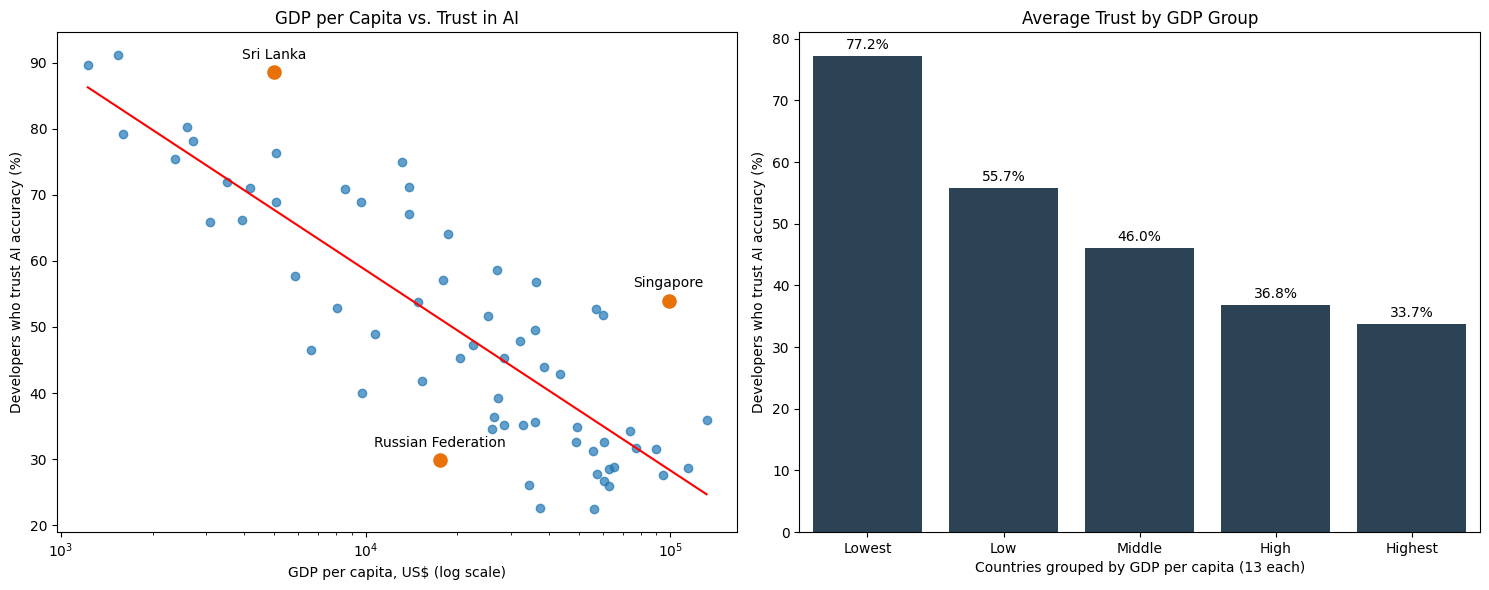

In [ ]:
gdp_labels = ["Lowest", "Low", "Middle", "High", "Highest"]

slope, intercept = np.polyfit(np.log10(country_trust["GDP_Per_Capita"]), country_trust["Trust_AI_Pct"], 1)
country_trust["Predicted"] = slope * np.log10(country_trust["GDP_Per_Capita"]) + intercept
country_trust["Gap"] = country_trust["Trust_AI_Pct"] - country_trust["Predicted"]
outliers = country_trust[country_trust["Gap"].abs() > 2 * country_trust["Gap"].std()]

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6))

left.scatter(country_trust["GDP_Per_Capita"], country_trust["Trust_AI_Pct"], alpha=0.7)
left.scatter(outliers["GDP_Per_Capita"], outliers["Trust_AI_Pct"], color="#E8710A", s=90)
for i in range(len(outliers)):
    left.text(outliers["GDP_Per_Capita"].iloc[i], outliers["Trust_AI_Pct"].iloc[i] + 2, outliers["Country_WB"].iloc[i], ha="center")
left.plot(country_trust["GDP_Per_Capita"], country_trust["Predicted"], color="red")
left.set_xscale("log")
left.set(title="GDP per Capita vs. Trust in AI", xlabel="GDP per capita, US$ (log scale)",
         ylabel="Developers who trust AI accuracy (%)")

sns.barplot(data=country_trust, x="Wealth_Group", y="Trust_AI_Pct", order=gdp_labels,
            color="#24445C", errorbar=None, ax=right)
right.bar_label(right.containers[0], fmt="%.1f%%", padding=3)
right.set(title="Average Trust by GDP Group", xlabel="Countries grouped by GDP per capita (13 each)",
          ylabel="Developers who trust AI accuracy (%)")

plt.tight_layout()
plt.show()

**6.1.1 GDP Per Capita Graph Key Takeaway:** Developers in wealthier countries trust AI accuracy less.

**Left Graph:** Each dot is a country. The trend line slopes down steeply: in the poorest countries, most developers trust AI output, while in the richest countries only about a third do. The highest trust is in Nepal (91.2%), Nigeria (89.7%), and Sri Lanka (88.6%), as shown in the table above.

**Right Graph:** We split the 65 countries into five equal GDP groups (13 countries each) and averaged the trust share in each group. Trust falls at every step: 77.2% in the poorest group, then 55.7%, 46.0%, 36.8%, and 33.7% in the richest group.

**6.1.1.1 GDP Per Capita Outliers**

In [ ]:
country_trust["Predicted"] = slope * np.log10(country_trust["GDP_Per_Capita"]) + intercept

country_trust["Gap"] = country_trust["Trust_AI_Pct"] - country_trust["Predicted"]

country_trust[["Country_WB",
               "GDP_Per_Capita",
               "Trust_AI_Pct",
               "Predicted",
               "Gap",
               "Respondents"]].sort_values("Gap").head(3)

,Country_WB,GDP_Per_Capita,Trust_AI_Pct,Predicted,Gap,Respondents
47,Russian Federation,17546.609375,29.807692,51.211324,-21.403631,104
18,Georgia,9691.534724,40.000000,59.031439,-19.031439,25
51,Slovenia,37376.221608,22.641509,41.249584,-18.608074,53


In [ ]:
typical_gap = country_trust["Gap"].std()
country_trust["Outlier"] = country_trust["Gap"].abs() > 2 * typical_gap

print(f"Typical gap: {round(typical_gap, 2)} points")
print(f"Outlier threshold: more than {round(2 * typical_gap, 2)} points from the line")
print(f"Outliers found: {country_trust['Outlier'].sum()}")

country_trust[country_trust["Outlier"]].sort_values("Gap")[
    ["Country_WB", "GDP_Per_Capita", "Trust_AI_Pct", "Predicted", "Gap", "Respondents"]
]

Typical gap: 10.41 points
Outlier threshold: more than 20.83 points from the line
Outliers found: 3


,Country_WB,GDP_Per_Capita,Trust_AI_Pct,Predicted,Gap,Respondents
47,Russian Federation,17546.609375,29.807692,51.211324,-21.403631,104
54,Sri Lanka,5002.079044,88.636364,67.744627,20.891736,44
49,Singapore,98813.978817,54.000000,28.441887,25.558113,50


**Outliers.** We compare each country's actual trust with what the trend line predicts from its GDP. The standard deviation of these gaps is 10.41 points, so we flag countries more than two standard deviations (20.83 points) from the line as outliers. Russia trusts AI much less than expected, while Sri Lanka and Singapore trust it much more.

**6.1.2 GDP Per Capita Section Takeaway:**

**Key Takeaway:** The richer the country, the less its developers trust AI (r = −0.83). Trust falls from 77.2% in the poorest group to 33.7% in the richest. Only Russia, Sri Lanka, and Singapore break the pattern.

**Process:** We removed neutral answers, counted "Highly trust" and "Somewhat trust" as trusting AI, and calculated the percent of trusting developers in each country. We then compared countries by GDP using a scatterplot and five equal GDP groups.

### 6.2: Do developers in richer countries use AI tools more? Do developers in poorer countries see AI as a bigger job threat?

This is the main test for our first question. For each country we calculate two shares: developers who use AI tools daily, and developers who answered "Yes" to "Is AI a threat to your current job?". Then we split the 65 countries into five equal GDP groups of 13 countries, the same groups as in 6.1.

In [ ]:
ai_data = merged_data[["Country_WB", "GDP_Per_Capita", "AISelect", "AIThreat"]].copy()
ai_data["Uses_AI_Daily"] = ai_data["AISelect"] == "Yes, I use AI tools daily"
ai_data["Sees_Threat"] = ai_data["AIThreat"] == "Yes"

country_summary = ai_data.groupby("Country_WB").agg({
    "GDP_Per_Capita": "first",
    "Uses_AI_Daily": "mean",
    "Sees_Threat": "mean"
}).reset_index()

country_summary = country_summary.rename(columns={
    "GDP_Per_Capita": "GDP",
    "Uses_AI_Daily": "Daily_AI_Pct",
    "Sees_Threat": "Threat_Pct"
})
country_summary["Daily_AI_Pct"] = country_summary["Daily_AI_Pct"] * 100
country_summary["Threat_Pct"] = country_summary["Threat_Pct"] * 100

labels = ["Lowest", "Low", "Middle", "High", "Highest"]
country_summary["GDP_Group"] = pd.qcut(country_summary["GDP"], q=5, labels=labels)

country_summary.groupby("GDP_Group")["GDP"].agg(["count", "min", "max"]).round(0)

/tmp/ipykernel_114521/4282790797.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  country_summary.groupby("GDP_Group")["GDP"].agg(["count", "min", "max"]).round(0)


,count,min,max
GDP_Group,,,
Lowest,13,1224.0,5066.0
Low,13,5866.0,17547.0
Middle,13,17995.0,32959.0
High,13,34418.0,57602.0
Highest,13,60337.0,131592.0


We take the average of the country percentages in each group, so every country counts the same. If we just put all developers together, the US would make up most of the richest group.

           Daily_AI_Pct  Threat_Pct
GDP_Group                          
Lowest             73.4        17.8
Low                59.8        13.8
Middle             54.8        12.5
High               51.4        14.5
Highest            47.0        10.8


/tmp/ipykernel_114521/1976516472.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_avg = country_summary.groupby("GDP_Group")[["Daily_AI_Pct", "Threat_Pct"]].mean().round(1)


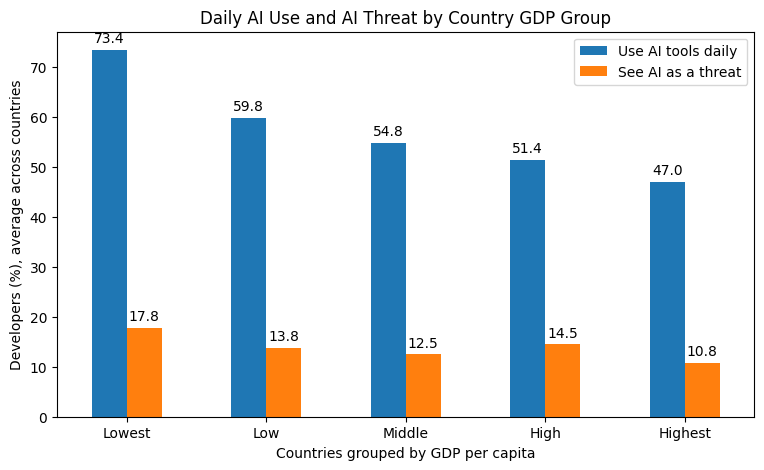

In [ ]:
group_avg = country_summary.groupby("GDP_Group")[["Daily_AI_Pct", "Threat_Pct"]].mean().round(1)
print(group_avg)

ax = group_avg.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Daily AI Use and AI Threat by Country GDP Group")
ax.set_xlabel("Countries grouped by GDP per capita")
ax.set_ylabel("Developers (%), average across countries")
ax.legend(["Use AI tools daily", "See AI as a threat"])
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.bar_label(ax.containers[1], fmt="%.1f", padding=3)
plt.show()

In [ ]:
log_gdp = np.log10(country_summary["GDP"])
print(f"log GDP vs daily AI use: r = {log_gdp.corr(country_summary['Daily_AI_Pct']):.2f}")
print(f"log GDP vs AI threat:    r = {log_gdp.corr(country_summary['Threat_Pct']):.2f}")

log GDP vs daily AI use: r = -0.81
log GDP vs AI threat:    r = -0.40


**6.2.1 Takeaway**: Developers in poorer countries are more likely to see AI as a threat to their job: 17.8% in the poorest group vs 10.8% in the richest (r = −0.40). The decline is not smooth, because the High group (14.5%) is above the Middle group (12.5%), so the link is only moderate. Developers in poorer countries also use AI tools daily much more often, and this share falls at every step, from 73.4% to 47.0% (r = −0.81).

**Process:** For each country, we calculated the share of developers who use AI tools daily and the share who answered "Yes" to the AI threat question. Then we split the 65 countries into five equal GDP groups of 13 countries (the same groups as in 6.1), averaged the country shares in each group, and measured the link with a Pearson correlation on log GDP.

### 6.3 Do developers who trust AI more feel less threatened by it?

We compare each developer's trust in AI accuracy with whether they see AI as a threat to their job. We keep only developers who gave a trust opinion and answered "Yes" or "No" to the threat question.

In [ ]:
trust_threat = merged_data[["AIAcc", "AIThreat"]].copy()

trust_threat = trust_threat[trust_threat["AIAcc"] != "Neither trust nor distrust"]
trust_threat = trust_threat[trust_threat["AIThreat"].isin(["Yes", "No"])]

trust_threat["Threat_Pct"] = (trust_threat["AIThreat"] == "Yes").astype(int) * 100

print("Developers:", len(trust_threat))
print(trust_threat.groupby("AIAcc")["Threat_Pct"].mean().round(2))

Developers: 14335
AIAcc
Highly distrust      12.23
Highly trust         35.96
Somewhat distrust    15.50
Somewhat trust       23.28
Name: Threat_Pct, dtype: float64


This cell keeps developers who gave a trust opinion and a clear Yes or No on the threat question, scores each “Yes” as 100 and each “No” as 0, then groups developers by trust level and averages those scores to get the percentage in each group who see AI as a threat to their job.

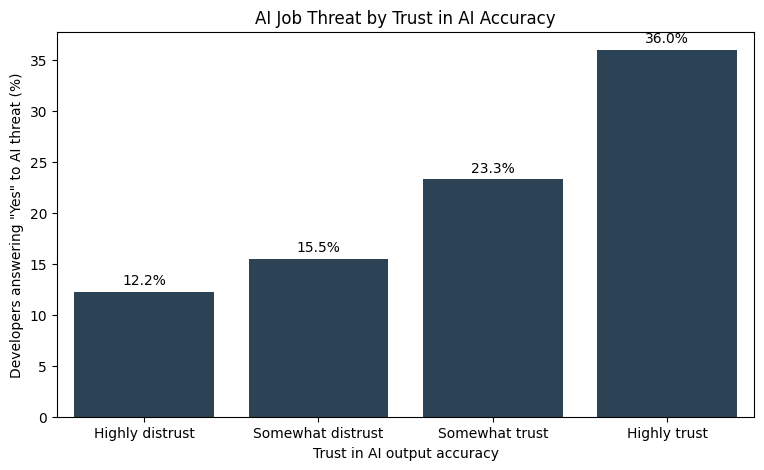

In [ ]:
trust_order = ["Highly distrust", "Somewhat distrust", "Somewhat trust", "Highly trust"]

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=trust_threat, x="AIAcc", y="Threat_Pct", order=trust_order, color="#24445C", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("AI Job Threat by Trust in AI Accuracy")
plt.xlabel("Trust in AI output accuracy")
plt.ylabel('Developers answering "Yes" to AI threat (%)')
plt.show()

**6.3.1 Takeaway:** The more a developer trusts AI's output, the more likely they are to see it as a threat to their job. Developers who highly trust AI are about three times as likely to see it as a threat to their job (36.0%) as those who highly distrust it (12.2%), and the share rises at every trust level. For stakeholders, this means building trust in AI tools will not by itself make developers feel secure, so employers need to address job security directly alongside AI adoption.

**Process:** We removed neutral trust answers and "I'm not sure" threat answers, then calculated the share of developers who answered "Yes" to the threat question at each trust level.

### 6.4: Which regions see AI as the biggest threat?

Next we grouped developers by World Bank region and calculated the share who answered "Yes" to the AI threat question.

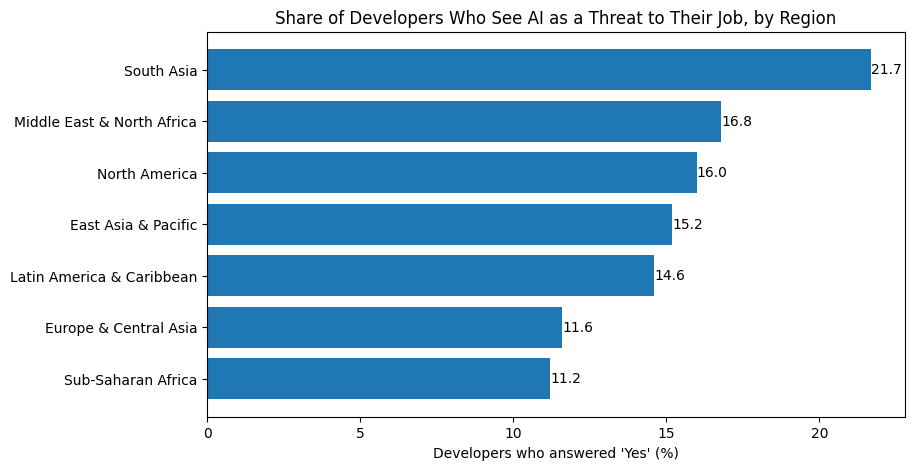

In [ ]:
region_data = merged_data[["Region", "Country_Code", "ResponseId", "AIThreat"]].copy()
region_data["Sees_Threat"] = region_data["AIThreat"] == "Yes"

region_summary = region_data.groupby("Region").agg({
    "Country_Code": "nunique",
    "ResponseId": "count",
    "Sees_Threat": "mean"
})

region_summary = region_summary.rename(columns={
    "Country_Code": "Countries",
    "ResponseId": "Respondents",
    "Sees_Threat": "Pct_Threat"
})
region_summary["Pct_Threat"] = (region_summary["Pct_Threat"] * 100).round(1)
region_summary = region_summary.sort_values("Pct_Threat")

plt.figure(figsize=(9, 5))
bars = plt.barh(region_summary.index, region_summary["Pct_Threat"])
plt.bar_label(bars, fmt="%.1f")
plt.title("Share of Developers Who See AI as a Threat to Their Job, by Region")
plt.xlabel("Developers who answered 'Yes' (%)")
plt.show()

**6.4.1 Takeaway**: South Asia has the highest share of developers who see AI as a threat (21.7%), while Sub-Saharan Africa (11.2%) and Europe & Central Asia (11.6%) are the lowest. Some regions are mostly one country, so see the limitations.

**Process:** We grouped developers by World Bank region and calculated the share who answered "Yes" to the AI threat question.

### 6.5: Do developers in more connected countries use AI tools more often?

In [ ]:
internet_ai_data = merged_data[["Country_Code", "Country_WB", "Internet_Usage_Pct", "AISelect", "ResponseId"]].copy()
internet_ai_data["Uses_AI_Daily"] = internet_ai_data["AISelect"] == "Yes, I use AI tools daily"

country_ai_use = internet_ai_data.groupby(["Country_Code", "Country_WB"]).agg({
    "Internet_Usage_Pct": "first",
    "Uses_AI_Daily": "mean",
    "ResponseId": "count"
}).reset_index()

country_ai_use = country_ai_use.rename(columns={
    "Uses_AI_Daily": "Daily_AI_Users_Pct",
    "ResponseId": "Respondents"
})
country_ai_use["Daily_AI_Users_Pct"] = country_ai_use["Daily_AI_Users_Pct"] * 100

print(f"Countries: {len(country_ai_use)}")
country_ai_use.sort_values("Daily_AI_Users_Pct", ascending=False).head()

Countries: 65


,Country_Code,Country_WB,Internet_Usage_Pct,Daily_AI_Users_Pct,Respondents
43,NPL,Nepal,46.321899,84.444444,45
15,EGY,"Egypt, Arab Rep.",74.648399,81.428571,70
40,NGA,Nigeria,41.211399,79.069767,86
35,LKA,Sri Lanka,54.590000,78.125000,64
45,PAK,Pakistan,57.253000,78.014184,141


In [ ]:
r_internet_ai = country_ai_use["Internet_Usage_Pct"].corr(country_ai_use["Daily_AI_Users_Pct"])
print(f"Internet usage vs daily AI use: r = {round(r_internet_ai, 2)}")

Internet usage vs daily AI use: r = -0.68


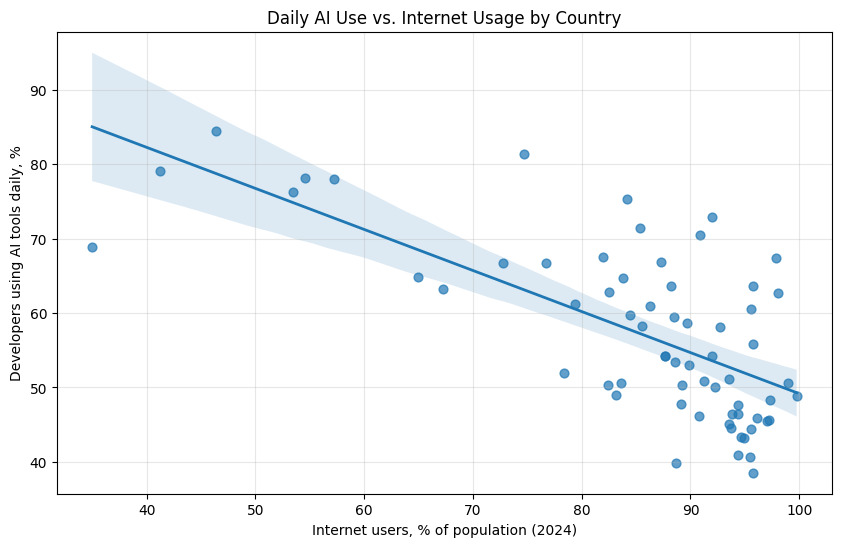

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=country_ai_use,
    x="Internet_Usage_Pct",
    y="Daily_AI_Users_Pct",
    scatter_kws={"s": 40, "alpha": 0.7},
    line_kws={"linewidth": 2}
)

plt.title(f"Daily AI Use vs. Internet Usage by Country")
plt.xlabel("Internet users, % of population (2024)")
plt.ylabel("Developers using AI tools daily, %")
plt.grid(alpha=0.3)
plt.show()

/tmp/ipykernel_114521/1002715488.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  internet_ai_avg = country_ai_use.groupby("Internet_Group")["Daily_AI_Users_Pct"].mean().round(2)


Internet_Group
Low       66.92
Medium    55.64
High      49.18
Name: Daily_AI_Users_Pct, dtype: float64


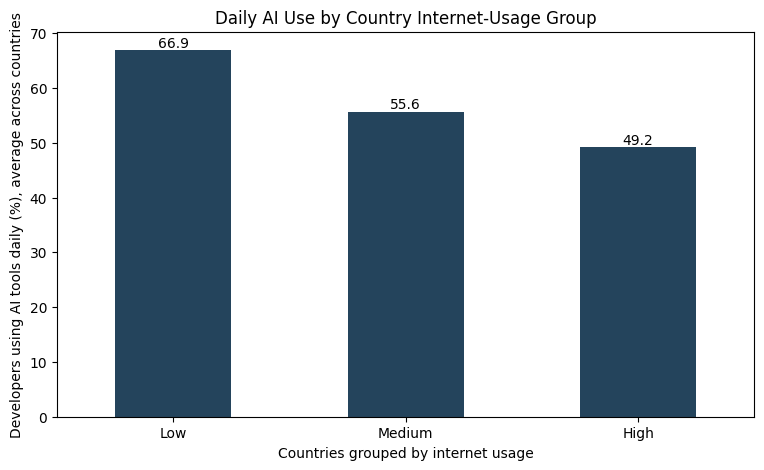

In [ ]:
country_ai_use["Internet_Group"] = pd.qcut(
    country_ai_use["Internet_Usage_Pct"],
    q=3,
    labels=["Low", "Medium", "High"]
)

internet_ai_avg = country_ai_use.groupby("Internet_Group")["Daily_AI_Users_Pct"].mean().round(2)
print(internet_ai_avg)

ax = internet_ai_avg.plot(kind='bar', figsize=(9, 5), rot=0, color='#24445C')
ax.set_title("Daily AI Use by Country Internet-Usage Group")
ax.set_xlabel("Countries grouped by internet usage")
ax.set_ylabel("Developers using AI tools daily (%), average across countries")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.show()

**6.5.1 Keytakeaway:**
Developers in more connected countries do not use AI tools more often. It is the opposite. The share of developers who use AI tools daily goes down as internet usage goes up. The highest daily use is in countries where less than 60% of people are online, such as Nepal, Nigeria, Sri Lanka, and Pakistan. This matches what we saw with GDP in 6.2, which makes sense because richer countries also tend to have higher internet usage.

### 6.6: Does higher national internet usage lower developers' perceived AI job threat?

In [ ]:
internet_threat_data = merged_data[["Country_Code", "Country_WB", "Internet_Usage_Pct", "AIThreat", "ResponseId"]].copy()
internet_threat_data["Sees_Threat"] = internet_threat_data["AIThreat"] == "Yes"

internet_country_summary = internet_threat_data.groupby(["Country_Code", "Country_WB"]).agg({
    "Internet_Usage_Pct": "first",
    "Sees_Threat": "mean",
    "ResponseId": "count"
}).reset_index()

internet_country_summary = internet_country_summary.rename(columns={
    "Country_WB": "Country_Name",
    "Sees_Threat": "AI_Threat_Pct",
    "ResponseId": "Respondents"
})
internet_country_summary["AI_Threat_Pct"] = internet_country_summary["AI_Threat_Pct"] * 100

print(internet_country_summary.shape)
internet_country_summary.head()

(65, 5)


,Country_Code,Country_Name,Internet_Usage_Pct,AI_Threat_Pct,Respondents
0,ARG,Argentina,89.667152,20.000000,150
1,AUS,Australia,96.131401,13.475177,564
2,AUT,Austria,94.919749,6.315789,285
3,BEL,Belgium,95.775791,10.091743,218
4,BGD,Bangladesh,53.421713,17.543860,114


In [ ]:
r_internet_threat = internet_country_summary["Internet_Usage_Pct"].corr(internet_country_summary["AI_Threat_Pct"])
print(f"Internet usage vs AI threat: r = {round(r_internet_threat, 2)}")

Internet usage vs AI threat: r = -0.32


In [ ]:
plot_data = internet_country_summary.copy()

plot_data["Internet_Group"] = pd.qcut(
    plot_data["Internet_Usage_Pct"],
    q=3,
    labels=["Low", "Medium", "High"]
)

order = ["Low", "Medium", "High"]

Segment countries into Low, Medium, and High groups using quantile based discretization based on their internet penetration rates.

In [ ]:
group_summary = plot_data.groupby("Internet_Group").agg({
    "Country_Code": "nunique",
    "AI_Threat_Pct": ["mean", "median"]
})
group_summary.columns = ["Countries", "Mean_Threat_Pct", "Median_Threat_Pct"]

group_summary

/tmp/ipykernel_114521/3690582229.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_summary = plot_data.groupby("Internet_Group").agg({


,Countries,Mean_Threat_Pct,Median_Threat_Pct
Internet_Group,,,
Low,22,16.006829,14.423648
Medium,21,12.932949,13.136289
High,22,12.677091,11.030008


In [ ]:
columns = [
    "Country_Name",
    "Country_Code",
    "Internet_Usage_Pct",
    "AI_Threat_Pct",
    "Respondents"
]

high_group = plot_data[plot_data["Internet_Group"] == "High"]

high_group[columns].sort_values("AI_Threat_Pct",
    ascending=False).head(10)

,Country_Name,Country_Code,Internet_Usage_Pct,AI_Threat_Pct,Respondents
34,"Korea, Rep.",KOR,97.895638,30.434783,46
28,Ireland,IRL,97.187698,18.354430,158
23,"Hong Kong SAR, China",HKG,95.755370,18.181818,44
61,United States,USA,94.693802,16.059271,4994
7,Canada,CAN,94.353302,15.340909,880
44,New Zealand,NZL,93.519302,14.285714,168
20,United Kingdom,GBR,95.472099,14.095372,1426
1,Australia,AUS,96.131401,13.475177,564
16,Spain,ESP,95.757452,12.500000,512
39,Malaysia,MYS,98.020606,11.764706,51


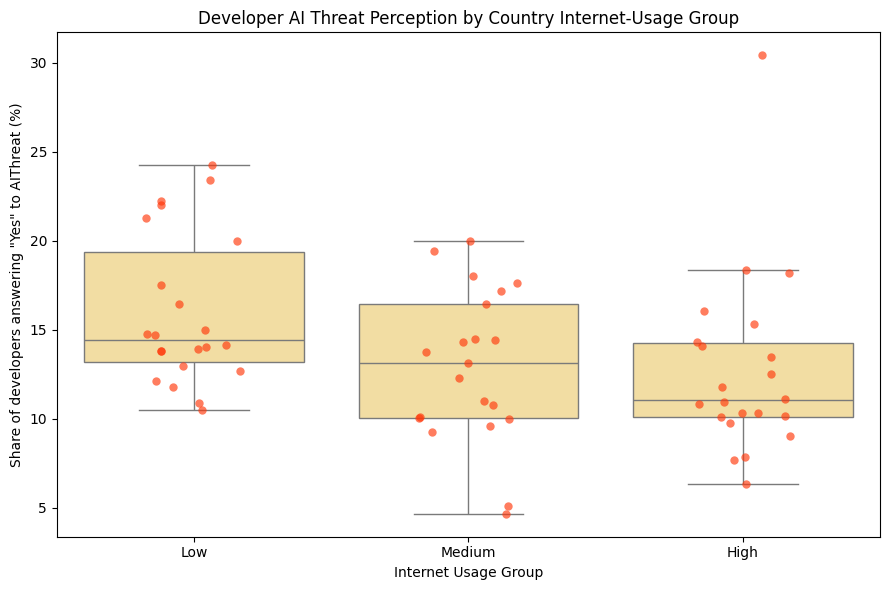

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=plot_data,
    x="Internet_Group",
    y="AI_Threat_Pct",
    order=order,
    color="#ffe396",
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=plot_data,
    x="Internet_Group",
    y="AI_Threat_Pct",
    order=order,
    color="#ff370a",
    alpha=0.65,
    jitter=0.18,
    size=6,
    ax=ax
)

ax.set_title(
    "Developer AI Threat Perception by Country Internet-Usage Group"
)
ax.set_xlabel("Internet Usage Group")
ax.set_ylabel('Share of developers answering "Yes" to AIThreat (%)')

plt.tight_layout()
plt.show()


**6.6.1 Takeaway**: This boxplot reveals that across all three groups, developers in lower internet coverage countries generally perceive a higher career threat from AI, while **South** **Korea** stands out as a high coverage country with unusually elevated threat levels.

**Process:** We started from dividing three balanced groups(Low, Medium and High) based on the internet usage rates. Then the box plot was generated to display the distribution of developers' perceived AI job threat rates.

### 6.7 Does internet usage remain associated with developers’ AI job threat perception when countries are compared within similar GDP levels?

Let's define what columns should contain in this analysis.

In [ ]:
analysis_data = merged_data[
    [
        "ResponseId",
        "Country_Code",
        "Country_WB",
        "GDP_Per_Capita",
        "Internet_Usage_Pct",
        "AIThreat"
    ]
].copy()

To avoid the responses "I'm not sure" be considered to "No", we use .isin to make sure we only use "Yes" and "No".

In [ ]:
analysis_data = analysis_data[analysis_data["AIThreat"].isin(["Yes", "No"])].copy()

analysis_data["AI_Threat_Yes"] = (analysis_data["AIThreat"] == "Yes").astype(int)

We need to convert individual GDP and internet usage data to the country level. We take the first entry for macro indicators per country, then calculate the mean AI threat and valid response counts. And we can convert the AI threat rate into percentage.

In [ ]:
country_analysis = analysis_data.groupby(["Country_Code", "Country_WB"]).agg({
    "GDP_Per_Capita": "first",
    "Internet_Usage_Pct": "first",
    "AI_Threat_Yes": "mean",
    "ResponseId": "count"
}).reset_index()

country_analysis = country_analysis.rename(columns={"ResponseId": "Valid_Responses"})
country_analysis["AI_Threat_Pct"] = country_analysis["AI_Threat_Yes"] * 100
country_analysis = country_analysis.drop(columns="AI_Threat_Yes")
country_analysis

,Country_Code,Country_WB,GDP_Per_Capita,Internet_Usage_Pct,Valid_Responses,AI_Threat_Pct
0,ARG,Argentina,14898.088594,89.667152,117,25.641026
1,AUS,Australia,65129.722799,96.131401,472,16.101695
2,AUT,Austria,62930.035132,94.919749,238,7.563025
3,BEL,Belgium,60750.273586,95.775791,177,12.429379
4,BGD,Bangladesh,2597.343523,53.421713,93,21.505376
...,...,...,...,...,...,...
60,URY,Uruguay,25215.823815,91.991090,23,21.739130
61,USA,United States,90026.516301,94.693802,4010,20.000000
62,VEN,"Venezuela, RB",3494.813887,76.678902,28,14.285714
63,VNM,Viet Nam,5065.990919,84.150000,55,21.818182


We divided the countries into five equal GDP groups of 13 countries, the same groups as in 6.1 and 6.2. This allows us to narrow down the range and examine the correlation between economic status, AI threat perception, and internet usage rates.

In [ ]:
gdp_order = [
    "Lowest",
    "Low",
    "Middle",
    "High",
    "Highest"
]

country_analysis["GDP_Group"] = pd.qcut(
    country_analysis["GDP_Per_Capita"],
    q=5,
    labels=gdp_order
)

country_analysis["GDP_Group"].value_counts().reindex(gdp_order)

,count
GDP_Group,
Lowest,13
Low,13
Middle,13
High,13
Highest,13


For each GDP group, we count the countries, average their internet usage and AI threat share, and measure the Pearson correlation between internet usage and AI threat. We also repeat the High group without South Korea, because it is a clear outlier in that group.

In [ ]:
correlation_table = country_analysis.groupby("GDP_Group").agg({
    "Country_Code": "count",
    "Internet_Usage_Pct": "mean",
    "AI_Threat_Pct": "mean"
})
correlation_table["Pearson_r"] = country_analysis.groupby("GDP_Group")["Internet_Usage_Pct"].corr(country_analysis["AI_Threat_Pct"])

correlation_table = correlation_table.rename(columns={
    "Country_Code": "Countries",
    "Internet_Usage_Pct": "Avg_Internet_Usage_Pct",
    "AI_Threat_Pct": "Avg_AI_Threat_Pct"
}).reset_index()

/tmp/ipykernel_114521/517758498.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  correlation_table = country_analysis.groupby("GDP_Group").agg({
/tmp/ipykernel_114521/517758498.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  correlation_table["Pearson_r"] = country_analysis.groupby("GDP_Group")["Internet_Usage_Pct"].corr(country_analysis["AI_Threat_Pct"])


In [ ]:
upper_middle_no_korea = country_analysis[
    (country_analysis["GDP_Group"] == "High")
    & (country_analysis["Country_WB"] != "Korea, Rep.")
]

korea_row = pd.DataFrame({
    "GDP_Group": ["High without South Korea"],
    "Countries": [len(upper_middle_no_korea)],
    "Avg_Internet_Usage_Pct": [upper_middle_no_korea["Internet_Usage_Pct"].mean()],
    "Avg_AI_Threat_Pct": [upper_middle_no_korea["AI_Threat_Pct"].mean()],
    "Pearson_r": [upper_middle_no_korea["Internet_Usage_Pct"].corr(upper_middle_no_korea["AI_Threat_Pct"])]
})

correlation_table = pd.concat([correlation_table, korea_row], ignore_index=True)
correlation_table.round({"Avg_Internet_Usage_Pct": 1, "Avg_AI_Threat_Pct": 1, "Pearson_r": 2})

,GDP_Group,Countries,Avg_Internet_Usage_Pct,Avg_AI_Threat_Pct,Pearson_r
0,Lowest,13,62.6,22.8,0.14
1,Low,13,86.6,17.5,0.18
2,Middle,13,89.3,16.5,-0.33
3,High,13,92.4,18.2,0.33
4,Highest,13,95.6,13.4,0.04
5,High without South Korea,12,91.9,16.8,-0.08


**6.7.1 Key Takeaway:** Internet usage does not have a consistent relationship with developers' AI job threat perception once countries are compared within similar GDP levels.Internet usage was only weakly related to AI job-threat perception in most GDP groups. The correlations were 0.14 in the Lowest group, 0.18 in the Low group, and 0.04 in the Highest group. The Middle group had a negative correlation of -0.33, while the High group had a positive correlation of 0.33. However, the High group result changed to -0.08 when South Korea was removed, so it may be driven by that one country. Therefore, internet usage alone does not reliably indicate how developers view AI-related job threats. AI companies, employers, and policymakers should also consider local factors such as AI adoption, labor-market conditions, job roles, and attitudes toward automation when planning training and workforce support.

### 6.8 How do developers’ trust in AI output accuracy and perceptions of AI as a job threat vary across age groups?

Age is not in our cleaned table, so we add it from the raw survey by ResponseId. We also group the five trust answers into Trust, Neutral and Distrust.

In [ ]:
age_trust_data = merged_data.merge(
    stack_overflow_raw_data[["ResponseId", "Age"]],
    on="ResponseId",
    how="left"
)

trust_mapping = {
    "Highly trust": "Trust",
    "Somewhat trust": "Trust",
    "Neither trust nor distrust": "Neutral",
    "Somewhat distrust": "Distrust",
    "Highly distrust": "Distrust"
}
age_trust_data["Trust_Group"] = age_trust_data["AIAcc"].map(trust_mapping)

In [ ]:
age_trust_data[
    ["ResponseId", "Age", "Trust_Group", "AIThreat"]
].head()

,ResponseId,Age,Trust_Group,AIThreat
0,1,25-34 years old,Neutral,I'm not sure
1,2,25-34 years old,Neutral,I'm not sure
2,3,35-44 years old,Trust,No
3,4,35-44 years old,Trust,No
4,5,35-44 years old,Neutral,No


In [ ]:
comparison_data = age_trust_data[
    age_trust_data["Age"].notna()
    & age_trust_data["Trust_Group"].notna()
    & age_trust_data["AIThreat"].isin(["Yes", "No"])
].copy()
print("Number of respondents:", len(comparison_data))

Number of respondents: 18017


In [ ]:
age_order = [
    "18-24 years old",
    "25-34 years old",
    "35-44 years old",
    "45-54 years old",
    "55-64 years old",
    "65 years or older"
]

In [ ]:
comparison_data = comparison_data[
    comparison_data["Age"].isin(age_order)
].copy()

comparison_data["Age"] = pd.Categorical(
    comparison_data["Age"],
    categories=age_order,
    ordered=True
)

In [ ]:
comparison_data["AI_Trust_Yes"] = (
    comparison_data["Trust_Group"] == "Trust"
).astype(int)
comparison_data["AI_Threat_Yes"] = (
    comparison_data["AIThreat"] == "Yes"
).astype(int)

In [ ]:
comparison_summary = comparison_data.groupby("Age").agg({
    "ResponseId": "count",
    "AI_Trust_Yes": "mean",
    "AI_Threat_Yes": "mean"
}).reset_index()

comparison_summary = comparison_summary.rename(columns={
    "ResponseId": "Valid_Responses",
    "AI_Trust_Yes": "AI_Trust_Pct",
    "AI_Threat_Yes": "AI_Threat_Pct"
})

comparison_summary["AI_Trust_Pct"] = comparison_summary["AI_Trust_Pct"] * 100
comparison_summary["AI_Threat_Pct"] = comparison_summary["AI_Threat_Pct"] * 100
comparison_summary

/tmp/ipykernel_114521/587826142.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  comparison_summary = comparison_data.groupby("Age").agg({


,Age,Valid_Responses,AI_Trust_Pct,AI_Threat_Pct
0,18-24 years old,2140,28.224299,17.056075
1,25-34 years old,6389,30.677727,16.747535
2,35-44 years old,5548,30.966114,18.493151
3,45-54 years old,2642,31.453444,19.530659
4,55-64 years old,1036,30.405405,16.216216
5,65 years or older,220,30.454545,10.909091


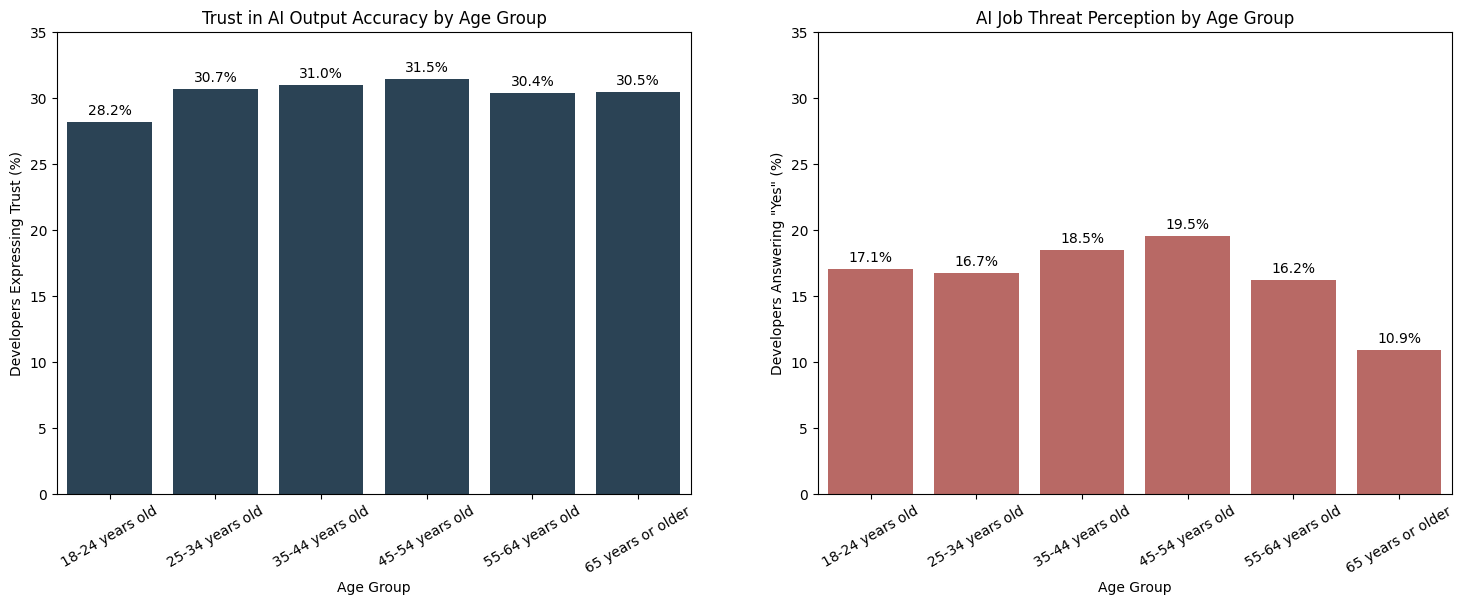

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=comparison_summary, x="Age", y="AI_Trust_Pct", color="#24445C", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].set_title("Trust in AI Output Accuracy by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Developers Expressing Trust (%)")
axes[0].set_ylim(0, 35)
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=comparison_summary, x="Age", y="AI_Threat_Pct", color="#C65D57", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set_title("AI Job Threat Perception by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel('Developers Answering "Yes" (%)')
axes[1].set_ylim(0, 35)
axes[1].tick_params(axis="x", rotation=30)

plt.show()

**6.8.1 Key Takeaway:**
AI trust remains relatively stable across age groups at approximately 28%–32%, while job threat perception varies more and peaks at 19.5% among 45–54 years old developers. This suggests that AI companies should build trust through accuracy and transparency for developers of all ages, while employers and policymakers should provide more targeted AI training, reskilling, and career support for mid-career developers. We kept neutral answers in this part, so trust shares are lower than in 6.1 and 6.9.

**Process:** We grouped respondents by age and calculated the percentage in each group who expressed trust in AI output accuracy or viewed AI as a job threat, keeping objective responses in the calculation.

### 6.9 Does the level of experience that developers have have an effect on the extent of their trust in AI?

We want to find out if developers who have gained more experience in coding have different opinions on AI from those who have less experience, since this could help us to decide whether AI training should differ between junior and senior developers.

In our analysis we used YearsCode as a measure of coding experience and AIAcc to measure trust; the neutral responses were excluded, as mentioned in Section 6.1.

In [ ]:
exp_data = merged_data[["ResponseId", "Country_WB", "GDP_Per_Capita", "YearsCode", "AIAcc"]].copy()
exp_data = exp_data[exp_data["AIAcc"] != "Neither trust nor distrust"]
exp_data["Trusts_AI"] = exp_data["AIAcc"].isin(["Somewhat trust", "Highly trust"])

# put developers into experience groups
exp_data["Exp_Group"] = pd.cut(exp_data["YearsCode"],
                               bins=[0, 4, 9, 14, 19, 29, 65],
                               labels=["0-4", "5-9", "10-14", "15-19", "20-29", "30+"])

exp_trust = exp_data.groupby("Exp_Group").agg({
    "Trusts_AI": "mean",
    "ResponseId": "count"
}).reset_index()

exp_trust = exp_trust.rename(columns={"Trusts_AI": "Trust_Pct", "ResponseId": "Developers"})
exp_trust["Trust_Pct"] = (exp_trust["Trust_Pct"] * 100).round(1)
exp_trust

/tmp/ipykernel_114521/3479982014.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_trust = exp_data.groupby("Exp_Group").agg({


,Exp_Group,Trust_Pct,Developers
0,0-4,60.7,812
1,5-9,46.1,3361
2,10-14,38.6,3727
3,15-19,38.7,2846
4,20-29,36.6,4001
5,30+,32.7,3200


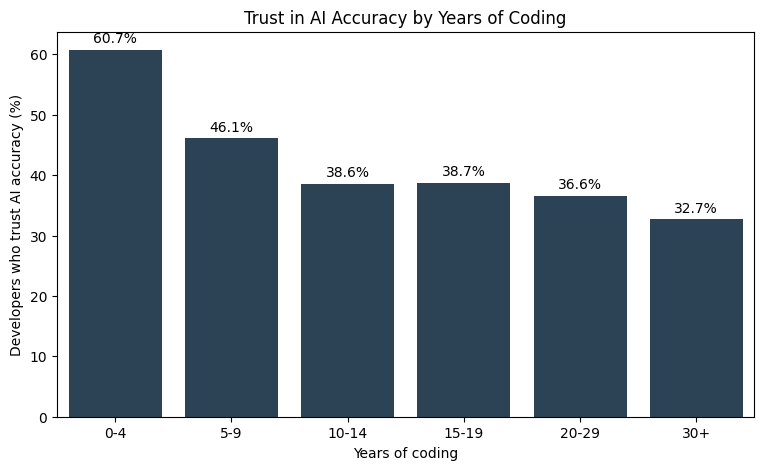

In [ ]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=exp_trust, x="Exp_Group", y="Trust_Pct", color="#24445C", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Trust in AI Accuracy by Years of Coding")
plt.xlabel("Years of coding")
plt.ylabel("Developers who trust AI accuracy (%)")
plt.show()

**6.9.1 Takeaway:**
The data indicates that developers with less experience are more inclined to trust AI; of those who have between 0 and 4 years' experience in coding, 60.7% trust the output of AI, whereas the figure drops to 32.7% among developers who have 30 years or more of experience. The biggest decline occurs in the first 10 years of experience, and thereafter the figures are comparable and range from about 33% to 39%.

**Process:** The developers are divided into six groups on the basis of the length of their coding experience and, having removed the neutral responses, the percentage of developers who trust AI is determined for each group.

### 6.10 Isn't the figure mentioned in 6.1 actually connected with experience?

As explained in Section 6.9, we noticed that developers who had more coding experience tended to trust AI less; this caused us to look into the possibility that the GDP results referred to in Section 6.1 might also be related to experience, since those developers in richer countries may have gained more coding experience.

To check this, we compared developers who had a similar level of experience among the five GDP groups mentioned in Section 6.1 and set out to find out whether the difference in AI trust between richer and poorer countries remained when developer experience was taken into account.

In [ ]:

country_gdp = exp_data.groupby("Country_WB")["GDP_Per_Capita"].first().sort_values()
gdp_groups = ["Lowest"] * 13 + ["Low"] * 13 + ["Middle"] * 13 + ["High"] * 13 + ["Highest"] * 13
country_to_group = dict(zip(country_gdp.index, gdp_groups))
exp_data["GDP_Group"] = exp_data["Country_WB"].map(country_to_group)

exp_data["Exp_Band"] = pd.cut(exp_data["YearsCode"], bins=[0, 9, 19, 65],
                              labels=["0-9 years", "10-19 years", "20+ years"])

print("Median years of coding in each GDP group:")
print(exp_data.groupby("GDP_Group")["YearsCode"].median().reindex(["Lowest", "Low", "Middle", "High", "Highest"]))

exp_gdp_trust = exp_data.groupby(["GDP_Group", "Exp_Band"])["Trusts_AI"].mean().unstack() * 100
exp_gdp_trust = exp_gdp_trust.reindex(["Lowest", "Low", "Middle", "High", "Highest"]).round(1)
exp_gdp_trust

Median years of coding in each GDP group:
GDP_Group
Lowest      9.0
Low        12.0
Middle     15.0
High       17.0
Highest    18.0
Name: YearsCode, dtype: float64


/tmp/ipykernel_114521/86201568.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_gdp_trust = exp_data.groupby(["GDP_Group", "Exp_Band"])["Trusts_AI"].mean().unstack() * 100


Exp_Band,0-9 years,10-19 years,20+ years
GDP_Group,,,
Lowest,79.0,76.9,72.3
Low,58.7,54.8,49.1
Middle,42.0,42.4,47.8
High,38.0,32.9,32.3
Highest,32.8,29.2,31.2


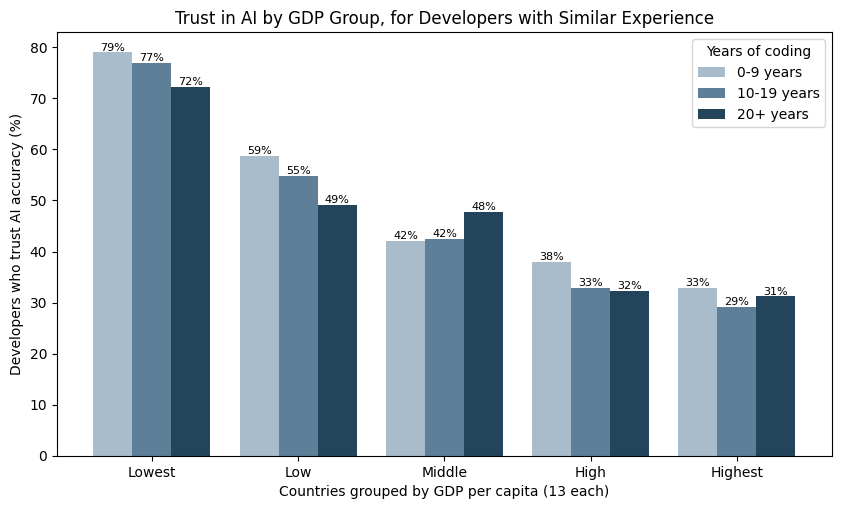

In [ ]:
ax = exp_gdp_trust.plot(kind="bar", figsize=(10, 5.5), rot=0, width=0.8,
                        color=["#a9bccb", "#5f7f99", "#24445C"])
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=8)
ax.bar_label(ax.containers[1], fmt="%.0f%%", fontsize=8)
ax.bar_label(ax.containers[2], fmt="%.0f%%", fontsize=8)
ax.set_title("Trust in AI by GDP Group, for Developers with Similar Experience")
ax.set_xlabel("Countries grouped by GDP per capita (13 each)")
ax.set_ylabel("Developers who trust AI accuracy (%)")
ax.legend(title="Years of coding")
plt.show()

**6.10.1 Takeaway:**
The results show that the quantity of coding experience does not completely explain the difference in AI trust between rich and poor countries. The median number of years of experience for developers in the group with the lowest GDP is 9, compared to 18 years for those in the group with the highest GDP. However, when developers who have similar levels of experience are compared, there is still a difference in AI trust. For example, among developers with 20 or more years' experience in coding, 72.3 per cent of those in the lowest GDP group place their trust in AI, while only 31.2 per cent of those belonging to the highest GDP group do. It thus shows that the relationship between GDP and AI trust is not entirely due to differences in coding experience.

**Process:** We used the five GDP groups as in Section 6.1 and divided the developers into three groups based on their level of experience. Then, for each level of experience, we compared the percentage of developers who trust AI among the different GDP groups.

### 6.11 What kinds of developers are most worried that AI is a threat to their jobs?

Different developer roles might have different concerns about AI taking their jobs. We would like to find out which positions are most at risk in order that employers may gain a better understanding of where AI training and career support are needed.

The developer roles were determined by referring to DevType and the degree of concern was assessed using AIThreat. In this analysis we have only included the "Yes" and "No" responses and have focused on the roles which had 300 developers or more. Furthermore, we have excluded the "Other" category.

In [ ]:
dev_data = merged_data[merged_data["AIThreat"].isin(["Yes", "No"])].copy()
dev_data["Sees_Threat"] = dev_data["AIThreat"] == "Yes"

dev_threat = dev_data.groupby("DevType").agg({
    "Sees_Threat": "mean",
    "ResponseId": "count"
}).reset_index()

dev_threat = dev_threat.rename(columns={"Sees_Threat": "Threat_Pct", "ResponseId": "Developers"})
dev_threat["Threat_Pct"] = (dev_threat["Threat_Pct"] * 100).round(1)

dev_threat = dev_threat[dev_threat["Developers"] >= 300]
dev_threat = dev_threat[dev_threat["DevType"] != "Other (please specify):"]

dev_threat["Job_Type"] = dev_threat["DevType"].str.replace("Developer, ", "").str.capitalize()
dev_threat["Job_Type"] = dev_threat["Job_Type"].str.replace("Devops", "DevOps")
dev_threat = dev_threat.sort_values("Threat_Pct", ascending=False).reset_index(drop=True)

all_dev_threat = round(dev_data["Sees_Threat"].mean() * 100, 1)
print("All developers:", all_dev_threat, "%")
dev_threat[["Job_Type", "Threat_Pct", "Developers"]]

All developers: 17.6 %


,Job_Type,Threat_Pct,Developers
0,Mobile,25.8,640
1,Front-end,24.1,848
2,Back-end,19.3,3247
3,Engineering manager,18.7,433
4,Full-stack,17.9,6314
5,"Architect, software or solutions",16.9,1307
6,Data engineer,16.6,343
7,Desktop or enterprise applications,13.8,1043
8,DevOps engineer or professional,12.3,424
9,Embedded applications or devices,10.0,709


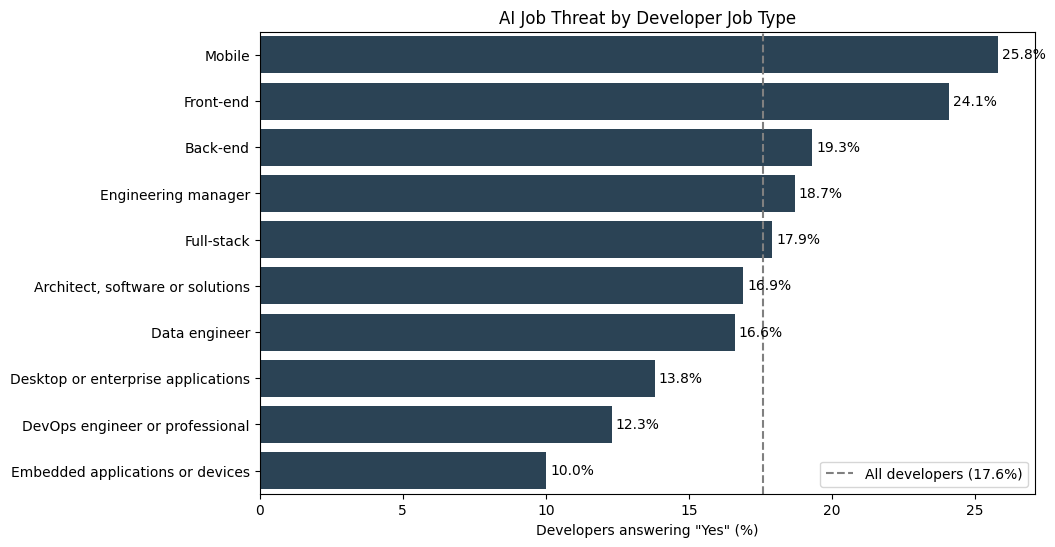

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=dev_threat, y="Job_Type", x="Threat_Pct", color="#24445C", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.axvline(all_dev_threat, color="gray", linestyle="--", label="All developers (" + str(all_dev_threat) + "%)")
plt.title("AI Job Threat by Developer Job Type")
plt.xlabel('Developers answering "Yes" (%)')
plt.ylabel("")
plt.legend(loc="lower right")
plt.show()

**6.11.1 Takeaway:**
Mobile developers are those who have the highest percentage of respondents who see AI as a threat to their jobs (25.8%), while front-end developers come next at 24.1%. On the other hand, only 10.0 per cent of embedded developers share this view. Mobile developers are therefore about 2.5 times more likely to say that AI is a threat to their jobs than embedded developers. Professions such as that of an embedded developer, a DevOps engineer, and a desktop developer show the least concern. It follows that companies should direct their AI training and career support towards mobile and front-end developers.

**Process:** We selected developer roles with at least 300 responses and removed the "Other" category. We then calculated the percentage of "Yes" answers for each role, using only respondents who answered either "Yes" or "No".

### 6.12 Confirming our findings with the LLM scores
Sections 6.1–6.6 measured trust and AI threat with single survey questions. To check those results, we use the two LLM scores from Section 5.2: LLM_Concern and LLM_Trust. Each score combines several survey answers, including attitudes toward AI and frustrations with AI, and LLM_Concern also uses "I'm not sure" threat answers. If the same patterns appear with these second measures, our findings are not just a result of how one survey question was worded.

#### 6.12.1 Do developers in lower GDP countries show more AI job concern?

We average the concern score for each country, then split the 65 countries into five equal GDP groups of 13, from lowest to highest GDP per capita.

In [ ]:
concern_data = merged_data[["Country_WB", "GDP_Per_Capita", "LLM_Concern"]].copy()

country_concern = concern_data.groupby("Country_WB").agg({
    "GDP_Per_Capita": "mean",
    "LLM_Concern": "mean"
}).reset_index()

country_concern = country_concern.sort_values("GDP_Per_Capita").reset_index(drop=True)
print("Countries:", len(country_concern))

country_concern.loc[0:12, "GDP_Group"] = "Lowest"
country_concern.loc[13:25, "GDP_Group"] = "Low"
country_concern.loc[26:38, "GDP_Group"] = "Middle"
country_concern.loc[39:51, "GDP_Group"] = "High"
country_concern.loc[52:64, "GDP_Group"] = "Highest"

print(country_concern.groupby("GDP_Group")["LLM_Concern"].mean().round(2))

Countries: 65
GDP_Group
High       3.41
Highest    3.13
Low        3.39
Lowest     3.73
Middle     3.44
Name: LLM_Concern, dtype: float64


This cell averages the LLM concern score for each country, sorts the countries from lowest to highest GDP per capita, and labels each block of 13 countries as one GDP group. It then averages the country scores within each group. Averaging by country first means the United States, with thousands of respondents, counts the same as a country with 30.

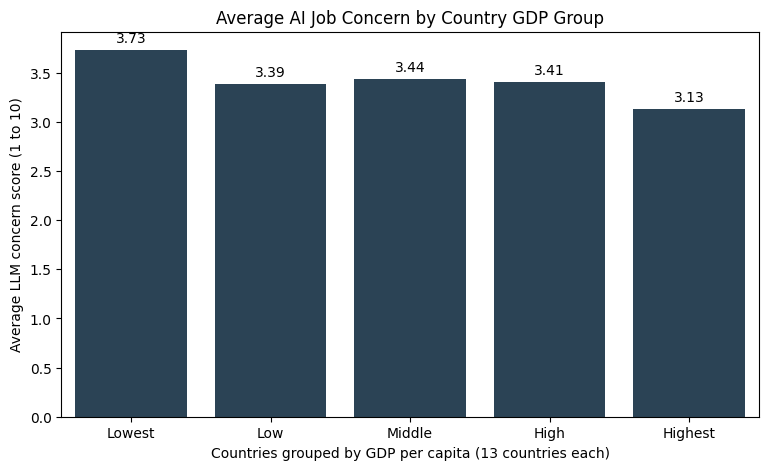

In [ ]:
gdp_labels = ["Lowest", "Low", "Middle", "High", "Highest"]

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=country_concern, x="GDP_Group", y="LLM_Concern", order=gdp_labels, color="#24445C", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Average AI Job Concern by Country GDP Group")
plt.xlabel("Countries grouped by GDP per capita (13 countries each)")
plt.ylabel("Average LLM concern score (1 to 10)")
plt.show()

**6.12.1 Takeaway:** Developers in the poorest countries are the most worried about AI taking their jobs (3.7 out of 10), and those in the richest countries are the least worried (3.1). The middle groups are about the same (3.4). This matches what we found in 6.2, so the result holds with two different measures. Concern is low overall, so employers and policymakers should focus upskilling and job security support on the lowest income markets, where worry is highest.

**Process:** We averaged the concern score for each country, split the 65 countries into five equal GDP groups of 13, and averaged the scores in each group.

#### 6.12.2: Do developers in less connected countries show higher AI concern and lower AI trust?

We use the two LLM scores from 5.2. For each country, we calculate the share of developers with a high score (7–10) on LLM_Concern and on LLM_Trust. Then we split the countries into Low, Medium and High internet usage groups and average the country shares in each group.

In [ ]:
internet_llm_data = merged_data[["Country_Code",
                                 "Country_WB",
                                 "Internet_Usage_Pct",
                                 "LLM_Concern",
                                 "LLM_Trust"]].copy()
internet_llm_data["High_Concern"] = internet_llm_data["LLM_Concern"] >= 7
internet_llm_data["High_Trust"] = internet_llm_data["LLM_Trust"] >= 7

country_llm_summary = internet_llm_data.groupby(["Country_Code", "Country_WB"]).agg({
    "Internet_Usage_Pct": "first",
    "High_Concern": "mean",
    "High_Trust": "mean"
}).reset_index()

country_llm_summary = country_llm_summary.rename(columns={
    "High_Concern": "High_Concern_Pct",
    "High_Trust": "High_Trust_Pct"
})
country_llm_summary["High_Concern_Pct"] = country_llm_summary["High_Concern_Pct"] * 100
country_llm_summary["High_Trust_Pct"] = country_llm_summary["High_Trust_Pct"] * 100

country_llm_summary["Internet_Group"] = pd.qcut(
    country_llm_summary["Internet_Usage_Pct"],
    q=3,
    labels=["Low", "Medium", "High"]
)

/tmp/ipykernel_114521/48956661.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  internet_llm_avg = country_llm_summary.groupby("Internet_Group")[["High_Concern_Pct", "High_Trust_Pct"]].mean().round(1)


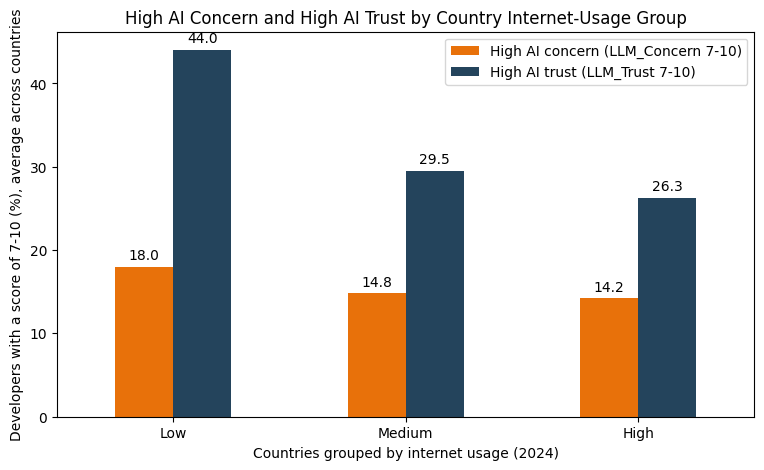

In [ ]:
internet_llm_avg = country_llm_summary.groupby("Internet_Group")[["High_Concern_Pct", "High_Trust_Pct"]].mean().round(1)

ax = internet_llm_avg.plot(kind="bar", figsize=(9, 5), rot=0, color=["#E8710A", "#24445C"])
ax.set_title("High AI Concern and High AI Trust by Country Internet-Usage Group")
ax.set_xlabel("Countries grouped by internet usage (2024)")
ax.set_ylabel("Developers with a score of 7-10 (%), average across countries")
ax.legend(["High AI concern (LLM_Concern 7-10)", "High AI trust (LLM_Trust 7-10)"])
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.bar_label(ax.containers[1], fmt="%.1f", padding=3)
plt.show()

**6.12.2 Takeaway:** Developers in the least connected countries stand out on both measures. In the Low internet usage group, 44.0% of developers have high trust in AI (LLM_Trust 7–10), compared with 29.5% in the Medium group and 26.3% in the High group. High concern about AI as a job threat moves in the same direction but the gap is much smaller: 18.0% in the Low group, compared with 14.8% in the Medium group and 14.2% in the High group. Most of the difference is between the Low group and the other two, while the Medium and High groups are very similar. This supports what we saw in 6.1 and 6.6: developers in less connected countries trust AI more and are also more worried about their jobs. Because LLM_Concern starts from the AIThreat answer, the concern bars mostly confirm the result from 6.6, while the trust gap is the stronger new finding.

## 7. Conclusion

The project examined the relationship between a country's level of wealth and its internet connectivity and the way its developers experience and perceive AI, specifically whether they feel threatened by it, how frequently they use it, and how much they trust it.

**The GDP per capita figure shows that people in poorer countries feel greater threat from AI and at the same time make greater use of it and place more trust in it.**

- 17.8% of developers among the poorest 20% of countries regard AI as a threat to their jobs, whereas only 10.8% of those in the richest 20% do (r = −0.40).
- 77.2% of developers among the poorest 20% of countries believe that AI is accurate, whereas only 33.7% of those in the richest 20% hold this view (r = −0.83).
- The use of AI tools is more frequent on a daily basis among developers in less wealthy countries (r = −0.81).

**The same pattern is observed in countries with less access to the Internet, but the effect is less pronounced.**

- 14.4% of developers in countries with low internet access regard AI as a threat to their jobs, whereas only 11.0% of developers in countries with high internet access see it that way (r = −0.32); these two groups' ranges overlap significantly.
- The use of AI tools is more frequent on a daily basis among developers in countries with less connectivity (correlation coefficient = −0.68).

**In summary, the people who depend most on AI are also the ones who are most concerned about it.** People in poorer and less well-connected countries are not avoiding the use of AI; rather, they make greater use of it and place more trust in it; even so, they think their job security is in danger because of it. There are two possible reasons for this. The first is that as developers in less wealthy countries use AI more often, they see directly what it can do and thus may become less sure of their own ability to match the performance of AI. The second is that a higher proportion of their work involves tasks which AI is already capable of carrying out. Nevertheless, our data is not good enough to allow us to test either of these explanations, so the question will have to be left for future research.

A number of countries fail to follow the pattern: South Korea, even though it is highly connected, has a high threat share (30.4 per cent, according to just 46 developers); Singapore and Sri Lanka place greater trust in AI than their level of wealth indicates, while Russia places considerably less trust in it.

**Caution:** The links referred to concern country averages and do not suggest causation. As wealthy countries are usually well connected, it is impossible to entirely separate the effect of wealth from that of internet access.

## 8. Actions

1. Loaded the 2025 Stack Overflow survey, 2025 GDP per capita, and 2024 Internet Usage data.
2. Cleaned and merged the datasets by country code.
3. Restricted the merged analysis to professional developers and countries with at least 30 respondents.
4. Summarized the survey responses at the country level.
5. Analyzed AI trust related questions and created several visualizations: scatter/regression plots for GDP per capita versus AI trust and Internet Usage versus daily AI tool use; bar charts comparing AI measures across GDP groups and regions; and a boxplot with country-level points comparing AI-threat percentages across Low, Medium, and High Internet Usage groups.
6. Scored every developer's AI trust and job concern with an LLM (gpt-6-luna) and used the scores to confirm our findings.
7. Compared AI trust and AI threat across age groups, years of coding and job types.

## 9. Limitations/Challenges

**9.1 Data Cleaning Limitations:**
1. Limited country scope. After data cleaning we are only left with 65 of 195 countries. The data can be partial or bias to these 65 countries and it is difficult to generalize.

**9.2 GDP to Stack Overflow Limitation:**
1. The chart shows that GDP and AI trust move together, not that wealth causes distrust. Other factors that come with wealth could still be the real driver.

2. The graphs tell us at the country level not at the individual level. Thus, you can't conclude that a well paid developer trusts AI less than a poorly paid one.

3. Some developers may work remotely for companies in richer countries, so their views could reflect the global job market more than their own country's economy.

4. There are regions that are only 1 country because of our cleaning. South Asia is mostly India and about 85% of North America is the US, so those bars mostly reflect one country.

5. The regions have very different amounts of data. Europe & Central Asia has 32 countries and 11,698 developers, while Sub-Saharan Africa only has 3 countries and 338 developers, so the smaller regions are less reliable.

**9.3 Internet Usage to Stack Overflow Limitations:**
1. Internet usage measures the whole population, not developers. Even in countries where few people are online, developers usually have good internet access, so the national rate does not show their real working conditions.

2. The survey has one row per developer, but the internet data has one row per country. To combine them, we had to average developers into country percentages, which shrinks tens of thousands of answers down to just 65 data points.

3. Most countries in our data have 80 to 100% of people online, and fewer than 10 are below 70%. So the results in 6.5 and 6.6 depend heavily on those few low-internet countries, and adding or removing just one could change the correlation noticeably.

**9.4 Data Limitations Broadly:**
1. These are Stack Overflow survey respondents, who are not a random sample of developers, especially in countries with few responses.

2. The World Bank has very little 2025 internet usage data yet, so we used 2024 values.

3. The API LLM scores are not new data. Both LLM_Trust and LLM_concern are based on core columns. So they can support our results but cannot prove them alone.

## 10. Next Steps

**Recommendations for Stakeholders**

1. Employers can focus support where concern was higher. Mobile and front-end developers reported the most concern about AI affecting their jobs, at 25.8% and 24.1%. Developers aged 45–54 also reported the highest concern among the age groups, at 19.5%. Employers can use these findings to start conversations and offer useful AI training and career support. They should ask employees what they need instead of assuming everyone in the same group feels the same way.
2. AI companies should build trust and speak clearly about job concerns. In the developers who strongly trusted AI accuracy, 36.0% also said AI threatened their jobs. Among those who strongly distrusted AI, the number was 12.2%. This shows that trust in AI does not always mean feeling secure about work. Companies can explain what AI tools can and cannot do, and how they may change employees’ work.
3. Policymakers and educators should consider local needs. In our country comparisons, developers in lower-GDP countries reported more daily AI use and more concern about AI threatening their jobs. But internet use did not show a clear pattern with job concerns when we compared countries with similar GDP levels. Training and job-support programs should be based on local needs such as education resources and other factors, not internet access alone.


**Future Research**

Future studies could collect more responses from each country and follow developers over time to see whether their views change. Researchers could also study GDP, internet use, age, coding experience, job type, and AI use together to see which factors are most closely linked to job concerns. Looking more closely at countries and job roles that stood out in this study, and adding data on developer pay and job openings, could help explain the results.

## 11. References
1. Stack Overflow. 2025 Developer Survey. https://github.com/StackExchange/Survey/tree/main/packages/archive
2. World Bank. GDP per capita (current US$). https://data.worldbank.org/indicator/NY.GDP.PCAP.CD
3. World Bank. Individuals using the Internet (% of population). https://data.worldbank.org/indicator/IT.NET.USER.ZS
4. World Bank. Country metadata (Region), included in the GDP file.

## 12. AI Disclosure Statement

### 12.1 AI Appendix
**1. Coding & Debugging support:**


* Claude was used for debugging and resolving errors, and to deepen our understanding of the concepts and terms involved, helping us define and understand each step before diving in. Claude was used across the project for Python syntax guidance, for resolving errors, for simplifying our code into clearer steps, and for structuring our data preparation and visualization code. All outputs were checked by the team.
* Claude was used for reviewing the notebook structure and making suggestions for improvements
* Claude was used as a Coding Assistant for vizualizations. We used claude to provide code templates for specific graphs and to improve vizual charachteristics of graphs, such as colors, labels and sizes.

**2. Analysis & Insight support:**

* Claude helped with recommendeding what graphs to use for the specific data or question we were trying to answer. For example, Claude recommended a country level scatter plot with a log scale for GDP and a threshold of two standard deviations from the trend line to flag outliers. However the team, chose which charts to use, which countries to label, and which threshold to apply.


**3. Writing & Documentation support:**

* Claude was used to outline the sections, check for grammatical errors, and test the write up for coherence. It was also used to stress test reasoning by challenging whether interpretations of the results were correct, and to help define the target audience for the analysis. The team evaluated Claude's feedback against the notebook's output before making any changes.
* We used Claude to improve the design of our graphs. We asked Claude to tell us which parameters we need to change (size, color, add labels) to make our graphs look better.
* Claude was used to help with organizing the Notebook and fixing minor problems, such as typos or grammar. For instance, we asked Claude to go trought the Notebook and find some typos or suggest a better order of our sections.
* We asked Claude to create a template for our slides in Stackoverflow colors and used it to make our slides. All of the graphs and text on our slides were written by human.

**4. Data enrichment with an LLM:**

* We used the OpenAI model gpt-6-luna to create two new columns for all 22,753 developers: LLM_Trust (trust in AI tools) and LLM_Concern (concern that AI threatens their job), both on a 1–10 scale. Claude was used to assist in creating the LLM scoring code. We decided to rely on Claude, because it costs money to run LLM through API and we wanted to be sure that we do not waste money. Claude gave us the raw code, it was rewritten by a human, only essential parts were kept, humans went through the code and added comments for better understanding of the code.

***All AI-generated content was carefully reviewed, edited, and verified by the team to ensure accuracy, originality, and compliance with academic integrity standards.***

